# IMC Prosperity 4 — Tutorial Round (Round 0) Analysis
## Products: EMERALDS & TOMATOES · Days: −2, −1

This notebook analyses the **actual tutorial round data** you already have.  
Its purpose is to build intuition about how Prosperity market data looks and behaves **before Round 2** so you know what signals to look for on new products.

### What this round teaches us
| Product | Known behaviour | Ideal strategy |
|---------|----------------|----------------|
| **EMERALDS** | Stationary around 10,000 — the textbook mean-reverting asset | Pure market-making / mean-reversion |
| **TOMATOES** | Drifting trend — price moves directionally across the day | Trend-following or adapted MM with directional bias |

---
## Table of Contents
1. Data Loading & Sanity Checks  
2. Mid-Price Time Series — Side-by-Side  
3. Return Distributions & Fat Tails  
4. Rolling Volatility Regime  
5. Order Book Microstructure (Spread, Depth, OBI)  
6. Stationarity & Mean-Reversion Tests  
7. Return Autocorrelation — What direction to fade or follow?  
8. Half-Life of Mean Reversion  
9. Market Trades Flow Analysis  
10. Cross-Product Correlation & Lead-Lag  
11. Day-over-Day Consistency (Day −2 vs Day −1)  
12. PnL Attribution  
13. Alpha Scorecard & Round 2 Takeaways  

---
## 1 — Data Loading & Sanity Checks

In [1]:
import subprocess, sys
def pip(pkg): subprocess.check_call([sys.executable,'-m','pip','install',pkg,'-q'])
for p in ['pandas','numpy','matplotlib','seaborn','scipy','statsmodels','plotly']:
    pip(p)

import warnings; warnings.filterwarnings('ignore')
import os, numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import norm
import statsmodels.api as sm
from statsmodels.tsa.stattools import adfuller, coint
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from IPython.display import display

plt.rcParams.update({
    'figure.dpi': 130, 'axes.grid': True, 'grid.alpha': 0.3,
    'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 10,
})
C = {'EMERALDS': '#2ecc71', 'TOMATOES': '#e74c3c'}  # consistent colours throughout
print('Libraries loaded ✓')

Libraries loaded ✓


DATA_DIR: /Users/saksh/Documents/GitHub/IMC Prosperity 4/TUTORIAL_ROUND_1
Exists:   True
Files:    ['prices_round_0_day_-2.csv', 'prices_round_0_day_-1.csv', 'trades_round_0_day_-1.csv', 'trades_round_0_day_-2.csv']
  ✓ /Users/saksh/Documents/GitHub/IMC Prosperity 4/TUTORIAL_ROUND_1/prices_round_0_day_-2.csv  (20,000 rows)
  ✓ /Users/saksh/Documents/GitHub/IMC Prosperity 4/TUTORIAL_ROUND_1/prices_round_0_day_-1.csv  (20,000 rows)
  ✓ /Users/saksh/Documents/GitHub/IMC Prosperity 4/TUTORIAL_ROUND_1/trades_round_0_day_-2.csv  (588 rows)
  ✓ /Users/saksh/Documents/GitHub/IMC Prosperity 4/TUTORIAL_ROUND_1/trades_round_0_day_-1.csv  (631 rows)

Prices shape : (40000, 19)
Trades shape : (1219, 9)


In [3]:
# ── QUICK SANITY CHECK ───────────────────────────────────────────────────────
summary = prices.groupby(['source_day','product']).agg(
    rows       = ('timestamp','count'),
    ts_min     = ('timestamp','min'),
    ts_max     = ('timestamp','max'),
    mid_mean   = ('mid_price','mean'),
    mid_std    = ('mid_price','std'),
    mid_min    = ('mid_price','min'),
    mid_max    = ('mid_price','max'),
    pnl_final  = ('profit_and_loss','last'),
    missing_mid= ('mid_price', lambda x: x.isna().sum()),
).round(2)

print('=== Price Data Summary by Day & Product ===')
display(summary)

print('\n>> Expected: EMERALDS mid ≈ 10,000 (stable); TOMATOES mid drifts across the day.')
print('>> If missing_mid > 0 there are data gaps — rare in Prosperity tutorial data.')

=== Price Data Summary by Day & Product ===


rows  ts_min  ts_max  mid_mean  mid_std  mid_min  \
source_day product                                                       
-2         EMERALDS  10000       0  999900  10000.00     0.73   9996.0   
           TOMATOES  10000       0  999900   5007.95    10.29   4988.0   
-1         EMERALDS  10000       0  999900  10000.00     0.72   9996.0   
           TOMATOES  10000       0  999900   4977.57    14.58   4946.5   

                     mid_max  pnl_final  missing_mid  
source_day product                                    
-2         EMERALDS  10004.0        0.0            0  
           TOMATOES   5036.0        0.0            0  
-1         EMERALDS  10004.0        0.0            0  
           TOMATOES   5011.0        0.0            0


>> Expected: EMERALDS mid ≈ 10,000 (stable); TOMATOES mid drifts across the day.
>> If missing_mid > 0 there are data gaps — rare in Prosperity tutorial data.


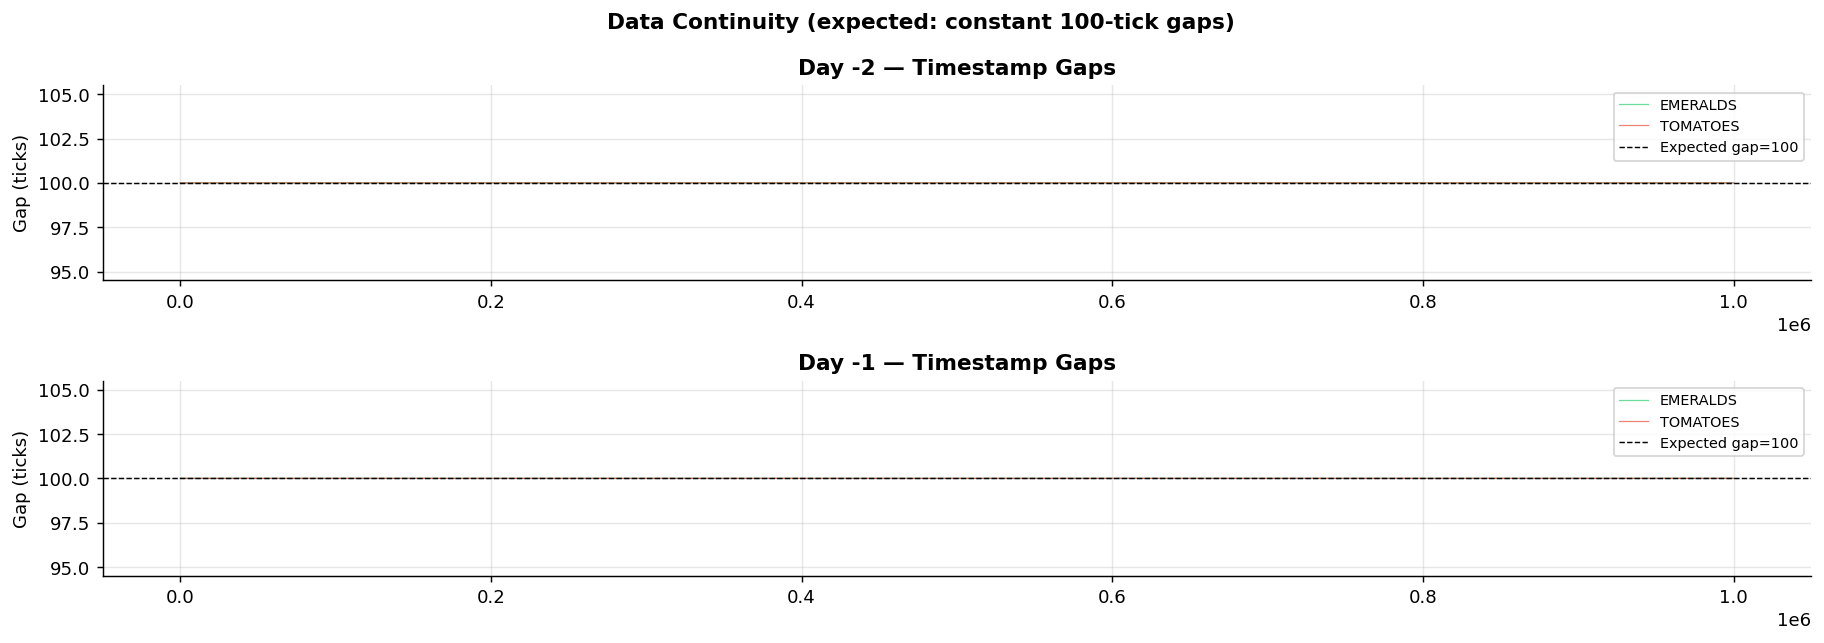

>> Spikes above 100 = missing rows. Flat line at 100 = perfect data.


In [4]:
# ── TIMESTAMP CONTINUITY ─────────────────────────────────────────────────────
# Each row should be exactly 100 ticks apart; gaps indicate missing data
fig, axes = plt.subplots(2, 1, figsize=(14, 5), sharex=False)
for ax, day in zip(axes, DAYS):
    for prod, colour in C.items():
        sub = prices[(prices['source_day']==day) & (prices['product']==prod)]
        gaps = sub['timestamp'].diff()
        ax.plot(sub['timestamp'], gaps, color=colour, label=prod, alpha=0.7, linewidth=0.7)
    ax.axhline(100, color='black', linestyle='--', linewidth=0.8, label='Expected gap=100')
    ax.set_title(f'Day {day} — Timestamp Gaps', fontweight='bold')
    ax.set_ylabel('Gap (ticks)')
    ax.legend(fontsize=8)
plt.suptitle('Data Continuity (expected: constant 100-tick gaps)', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()
print('>> Spikes above 100 = missing rows. Flat line at 100 = perfect data.')

---
## 2 — Mid-Price Time Series

This is your most important first look. EMERALDS should be flat around 10,000. TOMATOES should drift — both up and down across different days. This immediately tells you which strategy to use for each product.

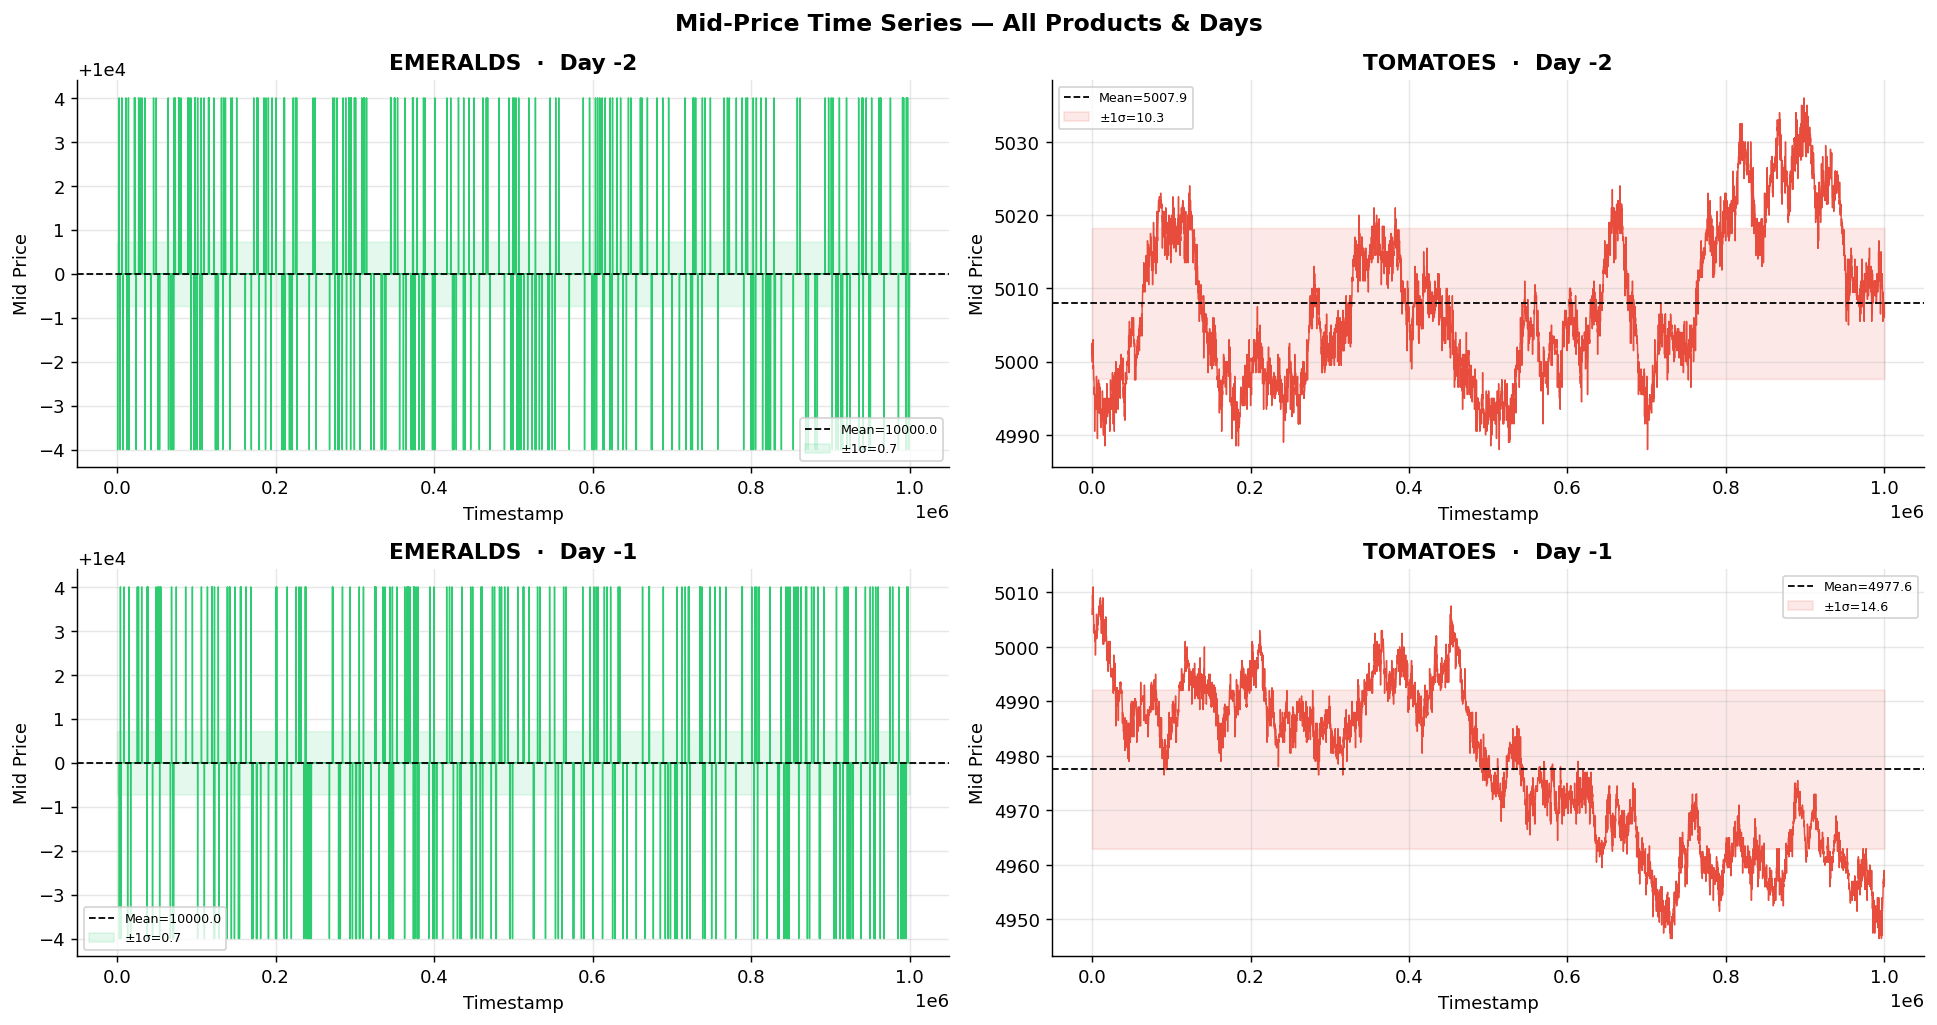

>> EMERALDS: expect a flat line near 10,000. The ±1σ band should be tight (< 20 units).
>> TOMATOES: expect a wandering price with wider swings. Check if the drift direction
   is the same across both days — if yes, there is a persistent intra-day trend to exploit.


In [5]:
fig, axes = plt.subplots(2, 2, figsize=(15, 8))

for col, prod in enumerate(PRODUCTS):
    for row, day in enumerate(DAYS):
        sub = prices[(prices['product']==prod) & (prices['source_day']==day)]
        ax  = axes[row][col]

        ax.plot(sub['timestamp'], sub['mid_price'], color=C[prod], linewidth=0.8)
        ax.axhline(sub['mid_price'].mean(), color='black', linestyle='--',
                   linewidth=1, label=f'Mean={sub["mid_price"].mean():.1f}')

        # Shade ±1σ band
        mu, sig = sub['mid_price'].mean(), sub['mid_price'].std()
        ax.fill_between(sub['timestamp'], mu-sig, mu+sig,
                         alpha=0.12, color=C[prod], label=f'±1σ={sig:.1f}')

        ax.set_title(f'{prod}  ·  Day {day}', fontweight='bold')
        ax.set_xlabel('Timestamp')
        ax.set_ylabel('Mid Price')
        ax.legend(fontsize=7)

plt.suptitle('Mid-Price Time Series — All Products & Days', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

print('>> EMERALDS: expect a flat line near 10,000. The ±1σ band should be tight (< 20 units).')
print('>> TOMATOES: expect a wandering price with wider swings. Check if the drift direction')
print('   is the same across both days — if yes, there is a persistent intra-day trend to exploit.')

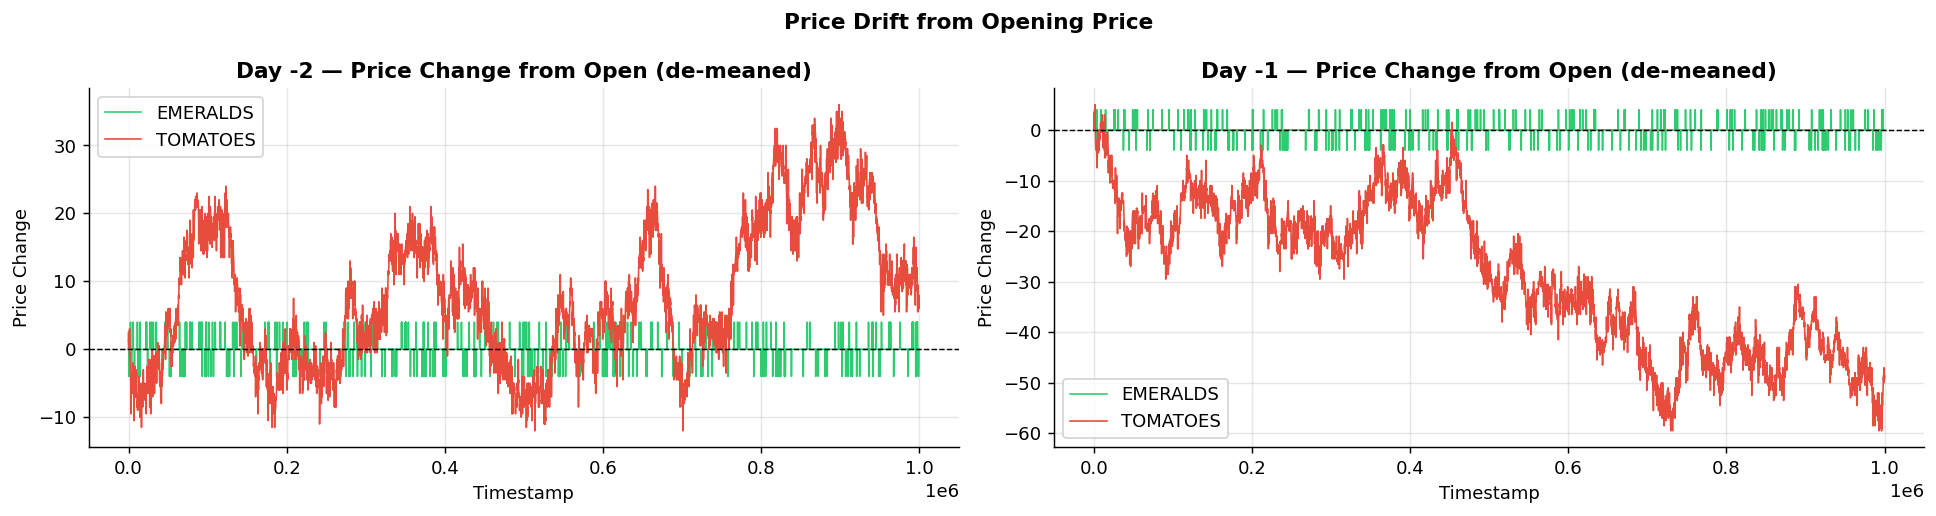

>> If TOMATOES consistently drifts in one direction, that is an intra-day trend signal.
>> EMERALDS should always return close to 0 — any sustained deviation is a market-making opportunity.


In [6]:
# ── CUMULATIVE PRICE CHANGE (de-meaned) ──────────────────────────────────────
# Removes starting-price differences so both products can be compared on the same axis
fig, axes = plt.subplots(1, 2, figsize=(15, 4), sharey=False)

for ax, day in zip(axes, DAYS):
    for prod, colour in C.items():
        sub = prices[(prices['product']==prod) & (prices['source_day']==day)].sort_values('timestamp')
        demeaned = sub['mid_price'] - sub['mid_price'].iloc[0]
        ax.plot(sub['timestamp'], demeaned, color=colour, label=prod, linewidth=0.9)
    ax.axhline(0, color='black', linewidth=0.8, linestyle='--')
    ax.set_title(f'Day {day} — Price Change from Open (de-meaned)', fontweight='bold')
    ax.set_xlabel('Timestamp')
    ax.set_ylabel('Price Change')
    ax.legend()

plt.suptitle('Price Drift from Opening Price', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()
print('>> If TOMATOES consistently drifts in one direction, that is an intra-day trend signal.')
print('>> EMERALDS should always return close to 0 — any sustained deviation is a market-making opportunity.')

---
## 3 — Return Distributions & Fat Tails

Tick-by-tick log returns. If returns have **fat tails** (excess kurtosis > 0), price jumps are more common than a normal distribution predicts — you need wider stop-losses and should not assume Gaussian risk.

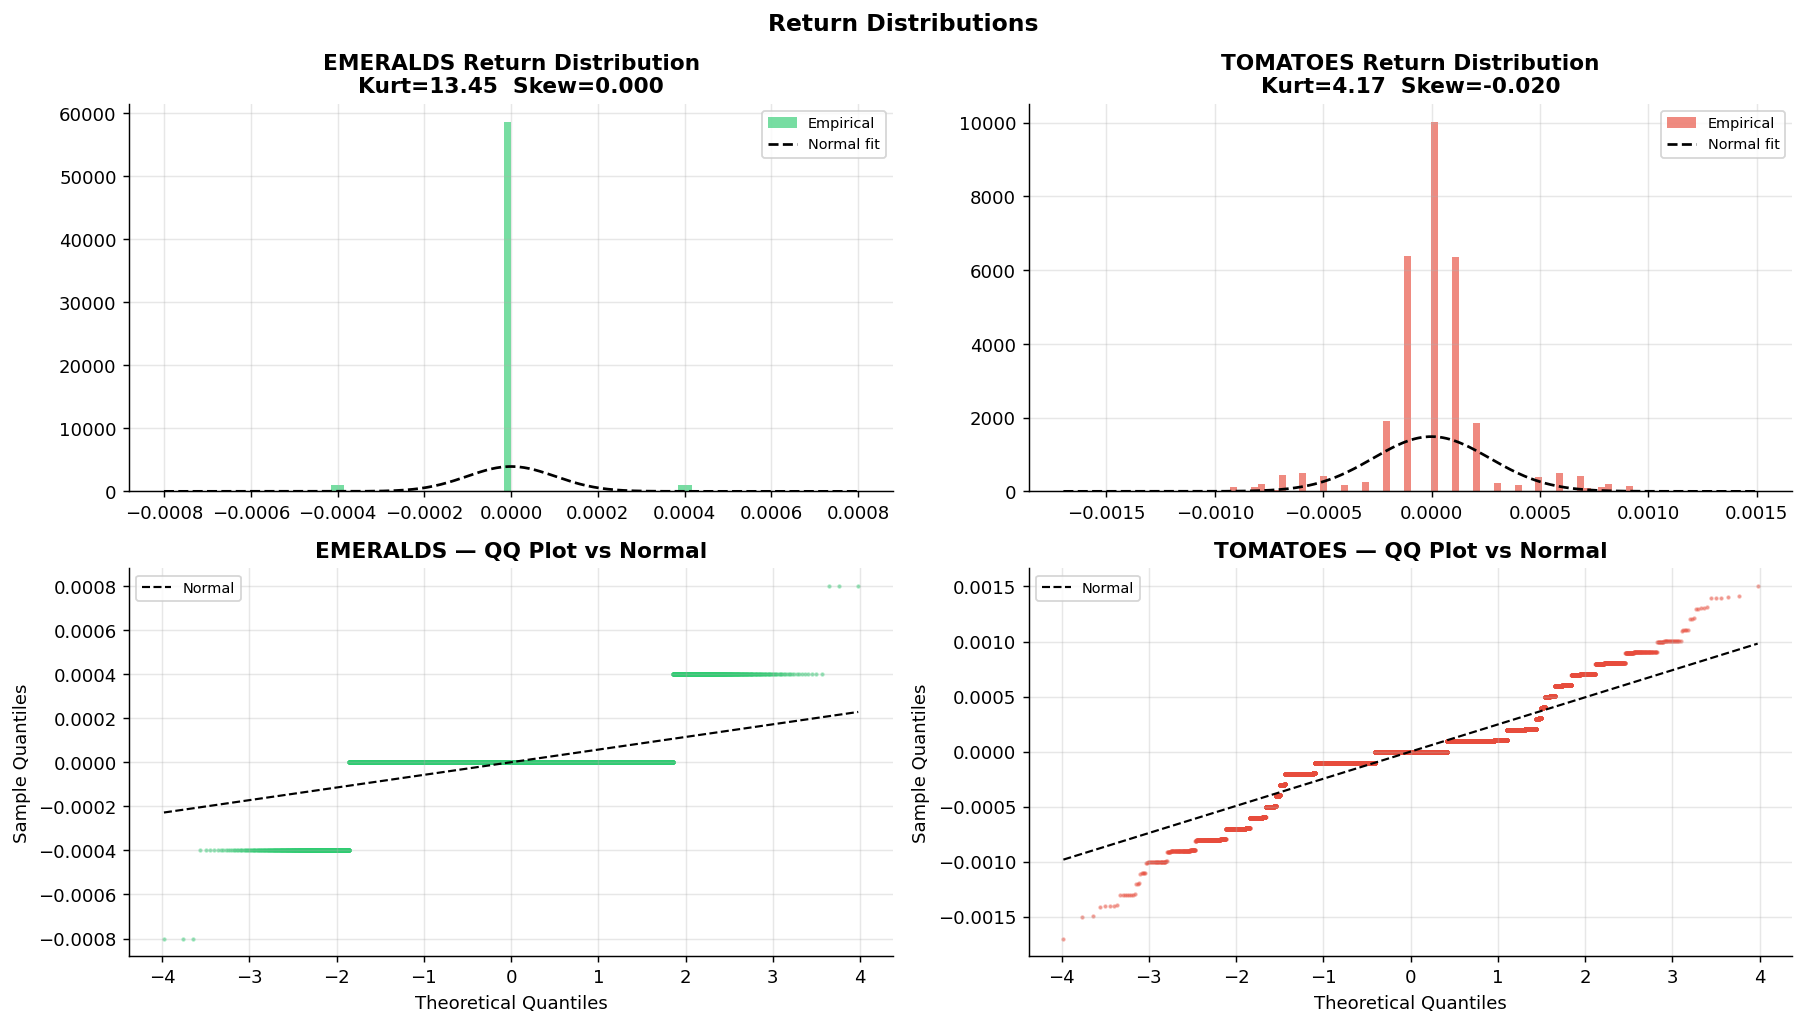

,mean,std,skewness,excess_kurtosis,annualised_vol
product,,,,,
EMERALDS,-0.0,0.000101,0.000000,13.452593,0.010136
TOMATOES,-0.0,0.000269,-0.019848,4.170001,0.026861



>> QQ plot: points on the line = normal. Curved S-shape = fat tails (kurtosis > 0).
>> Fat tails in EMERALDS mean occasional large spikes — great market-making opportunities.
>> Fat tails in TOMATOES mean momentum can extend further than expected — let winners run.


In [7]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
ret_stats = []

for col, prod in enumerate(PRODUCTS):
    sub = prices[prices['product']==prod].sort_values('abs_ts')
    ret = np.log(sub['mid_price'] / sub['mid_price'].shift(1)).dropna()

    mu, sig, skew, kurt = ret.mean(), ret.std(), ret.skew(), ret.kurtosis()
    ret_stats.append({'product':prod, 'mean':mu, 'std':sig,
                       'skewness':skew, 'excess_kurtosis':kurt,
                       'annualised_vol': sig*np.sqrt(TICKS_PER_DAY)})

    # Histogram vs Normal
    ax = axes[0][col]
    ax.hist(ret, bins=100, density=True, alpha=0.65, color=C[prod], label='Empirical')
    x = np.linspace(ret.min(), ret.max(), 400)
    ax.plot(x, norm.pdf(x, mu, sig), 'k--', linewidth=1.5, label='Normal fit')
    ax.set_title(f'{prod} Return Distribution\nKurt={kurt:.2f}  Skew={skew:.3f}',
                 fontweight='bold')
    ax.legend(fontsize=8)

    # QQ plot
    ax2 = axes[1][col]
    (osm, osr), (slope, intercept, r) = stats.probplot(ret, dist='norm')
    ax2.scatter(osm, osr, s=2, alpha=0.4, color=C[prod])
    ax2.plot(osm, slope*np.array(osm)+intercept, 'k--', linewidth=1.2, label='Normal')
    ax2.set_title(f'{prod} — QQ Plot vs Normal', fontweight='bold')
    ax2.set_xlabel('Theoretical Quantiles')
    ax2.set_ylabel('Sample Quantiles')
    ax2.legend(fontsize=8)

plt.suptitle('Return Distributions', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

display(pd.DataFrame(ret_stats).set_index('product').round(6))
print('\n>> QQ plot: points on the line = normal. Curved S-shape = fat tails (kurtosis > 0).')
print('>> Fat tails in EMERALDS mean occasional large spikes — great market-making opportunities.')
print('>> Fat tails in TOMATOES mean momentum can extend further than expected — let winners run.')

---
## 4 — Rolling Volatility Regime

Volatility clustering reveals when the market is calm vs. turbulent. During high-vol regimes:
- Market makers should **widen their quotes** to avoid being picked off
- Position limits should be **reduced** to cap drawdown risk

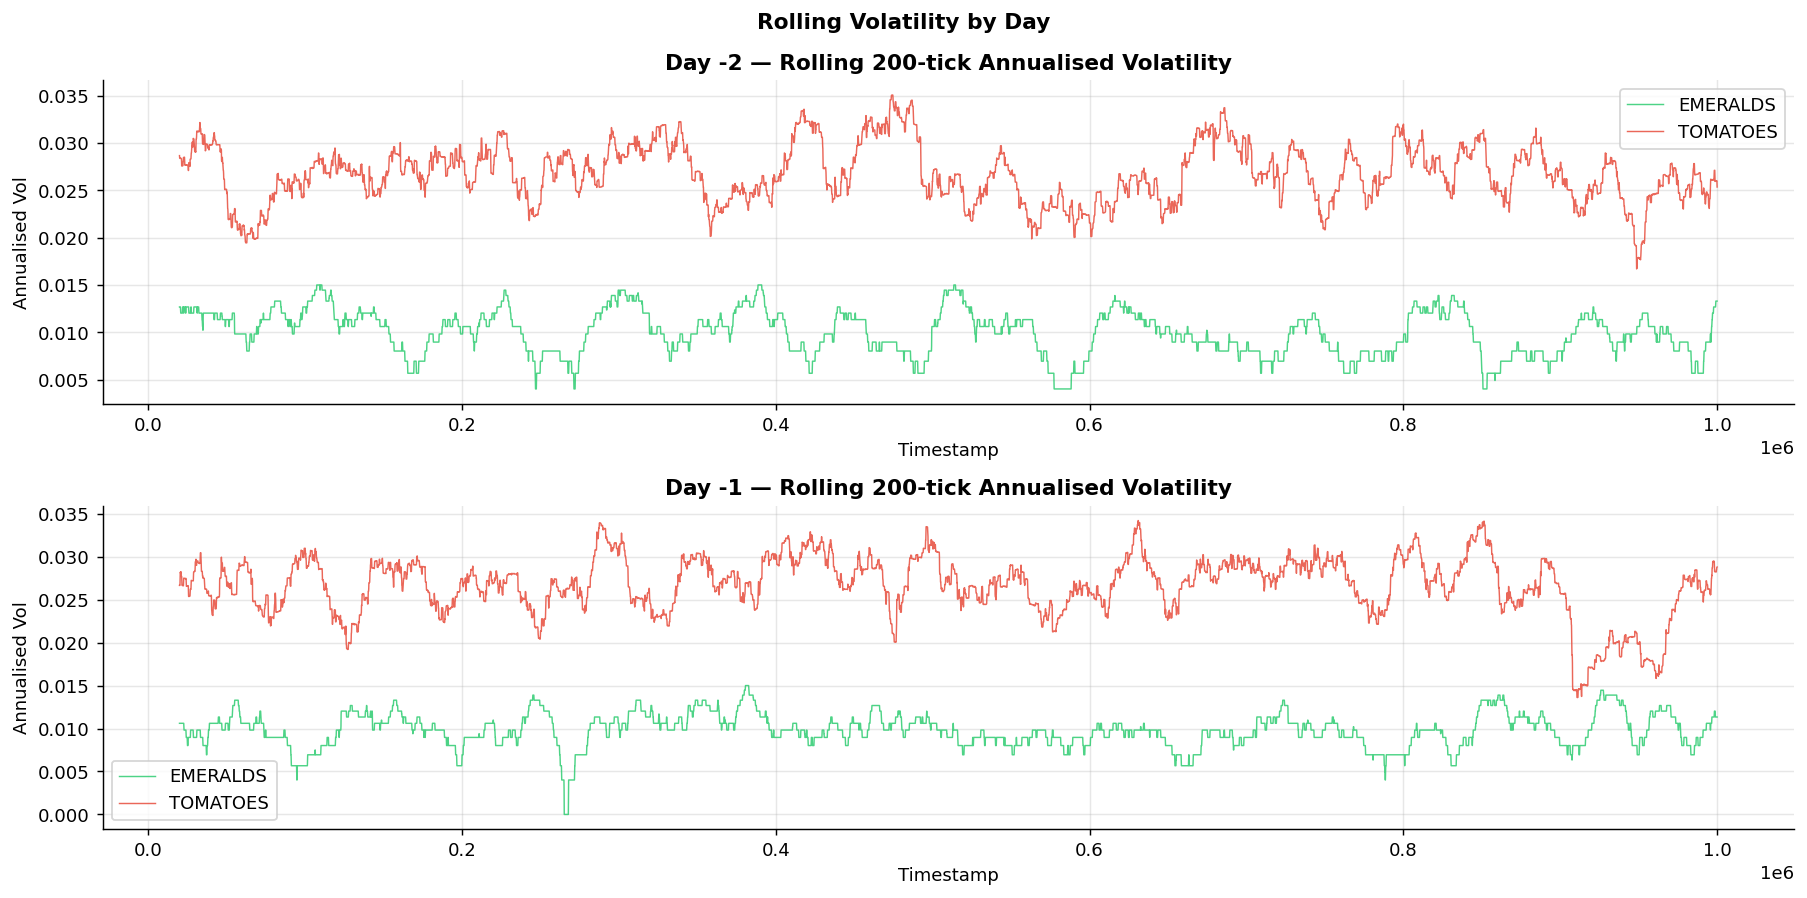

>> EMERALDS: vol should be low and stable (little spread for MM profit, but consistent).
>> TOMATOES: vol bursts likely coincide with trend acceleration — use them to confirm entries.
>> If vol is similar between days for the same product, regime is stable → signal is repeatable.


In [8]:
ROLL = 200  # 200 ticks = 20 seconds of market time

fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=False)

for ax, day in zip(axes, DAYS):
    for prod, colour in C.items():
        sub = prices[(prices['product']==prod) & (prices['source_day']==day)].sort_values('timestamp')
        ret = np.log(sub['mid_price'] / sub['mid_price'].shift(1))
        vol = ret.rolling(ROLL).std() * np.sqrt(TICKS_PER_DAY)  # annualised
        ax.plot(sub['timestamp'], vol, color=colour, label=prod, linewidth=0.8, alpha=0.85)

    ax.set_title(f'Day {day} — Rolling {ROLL}-tick Annualised Volatility', fontweight='bold')
    ax.set_ylabel('Annualised Vol')
    ax.set_xlabel('Timestamp')
    ax.legend()

plt.suptitle('Rolling Volatility by Day', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

print(f'>> EMERALDS: vol should be low and stable (little spread for MM profit, but consistent).')
print(f'>> TOMATOES: vol bursts likely coincide with trend acceleration — use them to confirm entries.')
print(f'>> If vol is similar between days for the same product, regime is stable → signal is repeatable.')

In [9]:
# ── VOLATILITY PERSISTENCE TEST (ARCH effect) ────────────────────────────────
# Squared returns should have positive autocorrelation if volatility clusters
from statsmodels.stats.diagnostic import het_arch

print('=== ARCH Effect Test (Volatility Clustering) ===')
for prod in PRODUCTS:
    sub = prices[prices['product']==prod].sort_values('abs_ts')
    ret = np.log(sub['mid_price'] / sub['mid_price'].shift(1)).dropna()
    stat, p, _, _ = het_arch(ret, nlags=10)
    clustered = p < 0.05
    print(f'  {prod:12s}: ARCH stat={stat:.2f}  p={p:.4f}  '
          f'→ {"VOLATILITY CLUSTERING" if clustered else "no strong clustering"}')

print('\n>> ARCH effect present (p<0.05): high-vol follows high-vol.')
print('>> Strategy: after a large price move, temporarily widen MM quotes or reduce position size.')

=== ARCH Effect Test (Volatility Clustering) ===
  EMERALDS    : ARCH stat=6215.97  p=0.0000  → VOLATILITY CLUSTERING
  TOMATOES    : ARCH stat=4000.83  p=0.0000  → VOLATILITY CLUSTERING

>> ARCH effect present (p<0.05): high-vol follows high-vol.
>> Strategy: after a large price move, temporarily widen MM quotes or reduce position size.


---
## 5 — Order Book Microstructure

### 5a — Bid-Ask Spread
Your gross profit from a round-trip market-making trade equals the spread. Your **net profit** equals spread minus position costs. If the spread is always 1 tick, you have a very thin cushion — you need a strong signal to enter.

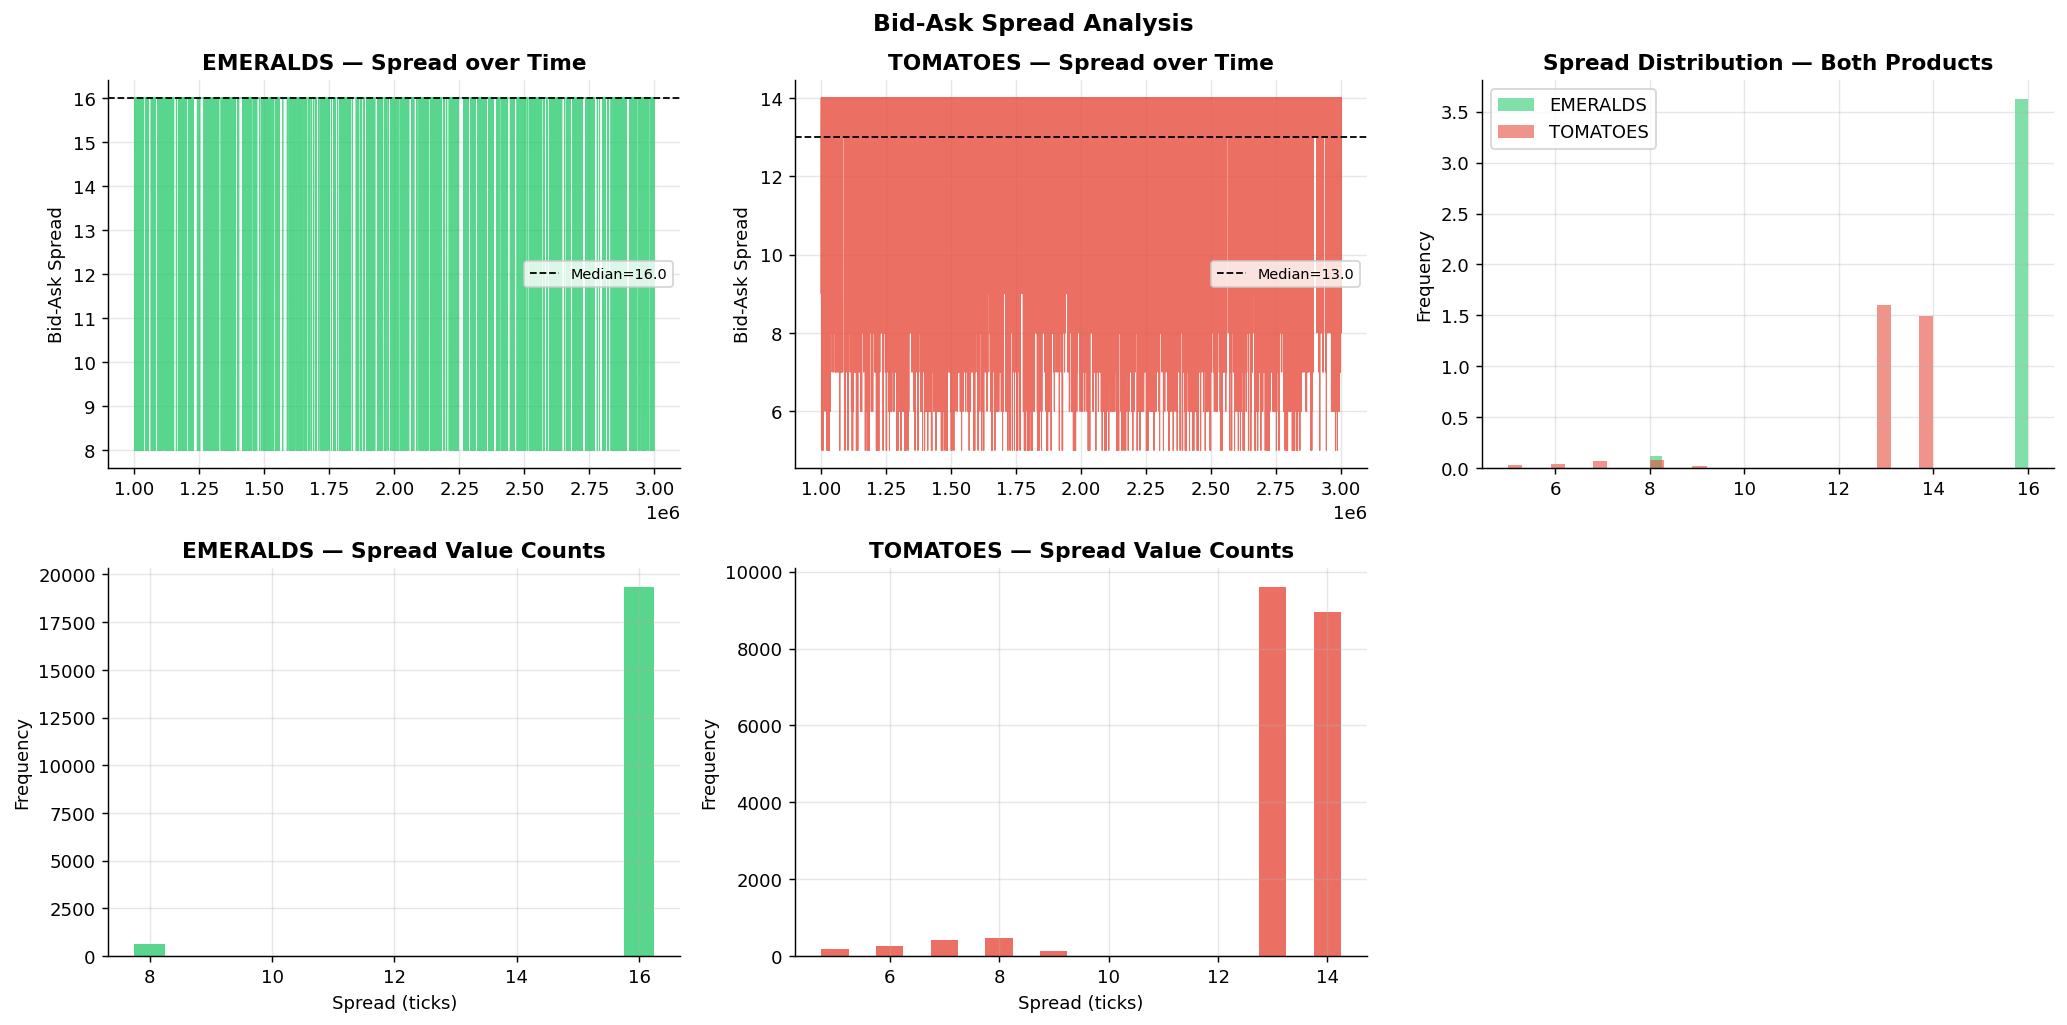

,mean_spread,median_spread,min_spread,max_spread,spread_std,pct_1tick,pct_spread
product,,,,,,,
EMERALDS,15.7384,16.0,8,16,1.4228,0.0,0.1574
TOMATOES,13.0203,13.0,5,14,1.7546,0.0,0.2608



>> pct_1tick: % of time spread = 1 tick. High % → book is almost always tight.
>> pct_spread: relative spread as % of price — true cost of crossing.
>> If spread is always 16 for EMERALDS (ask=10008, bid=9992), post quotes between those!


In [10]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
spread_stats = []

for col, prod in enumerate(PRODUCTS):
    sub = prices[prices['product']==prod].copy()
    sub['spread'] = sub['ask_price_1'] - sub['bid_price_1']

    spread_stats.append({
        'product'      : prod,
        'mean_spread'  : sub['spread'].mean(),
        'median_spread': sub['spread'].median(),
        'min_spread'   : sub['spread'].min(),
        'max_spread'   : sub['spread'].max(),
        'spread_std'   : sub['spread'].std(),
        'pct_1tick'    : (sub['spread']==1).mean()*100,
        'pct_spread'   : sub['spread'].mean() / sub['mid_price'].mean() * 100,
    })

    # Time series
    ax0 = axes[0][col]
    ax0.plot(sub['abs_ts'], sub['spread'], color=C[prod], linewidth=0.6, alpha=0.8)
    ax0.axhline(sub['spread'].median(), color='black', linestyle='--', linewidth=1,
                label=f'Median={sub["spread"].median():.1f}')
    ax0.set_title(f'{prod} — Spread over Time', fontweight='bold')
    ax0.set_ylabel('Bid-Ask Spread')
    ax0.legend(fontsize=8)

    # Distribution
    ax1 = axes[1][col]
    spread_vals = sub['spread'].dropna()
    unique_vals = sorted(spread_vals.unique())
    counts = [( spread_vals==v).sum() for v in unique_vals]
    ax1.bar(unique_vals, counts, color=C[prod], alpha=0.8, width=0.5)
    ax1.set_title(f'{prod} — Spread Value Counts', fontweight='bold')
    ax1.set_xlabel('Spread (ticks)')
    ax1.set_ylabel('Frequency')

# Combined spread distribution
ax2 = axes[0][2]
for prod in PRODUCTS:
    sub = prices[prices['product']==prod].copy()
    sub['spread'] = sub['ask_price_1'] - sub['bid_price_1']
    sub['spread'].plot.hist(bins=30, ax=ax2, alpha=0.6, color=C[prod], label=prod, density=True)
ax2.set_title('Spread Distribution — Both Products', fontweight='bold')
ax2.legend()

axes[1][2].set_visible(False)

plt.suptitle('Bid-Ask Spread Analysis', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

spread_df = pd.DataFrame(spread_stats).set_index('product')
display(spread_df.round(4))
print('\n>> pct_1tick: % of time spread = 1 tick. High % → book is almost always tight.')
print('>> pct_spread: relative spread as % of price — true cost of crossing.')
print('>> If spread is always 16 for EMERALDS (ask=10008, bid=9992), post quotes between those!')

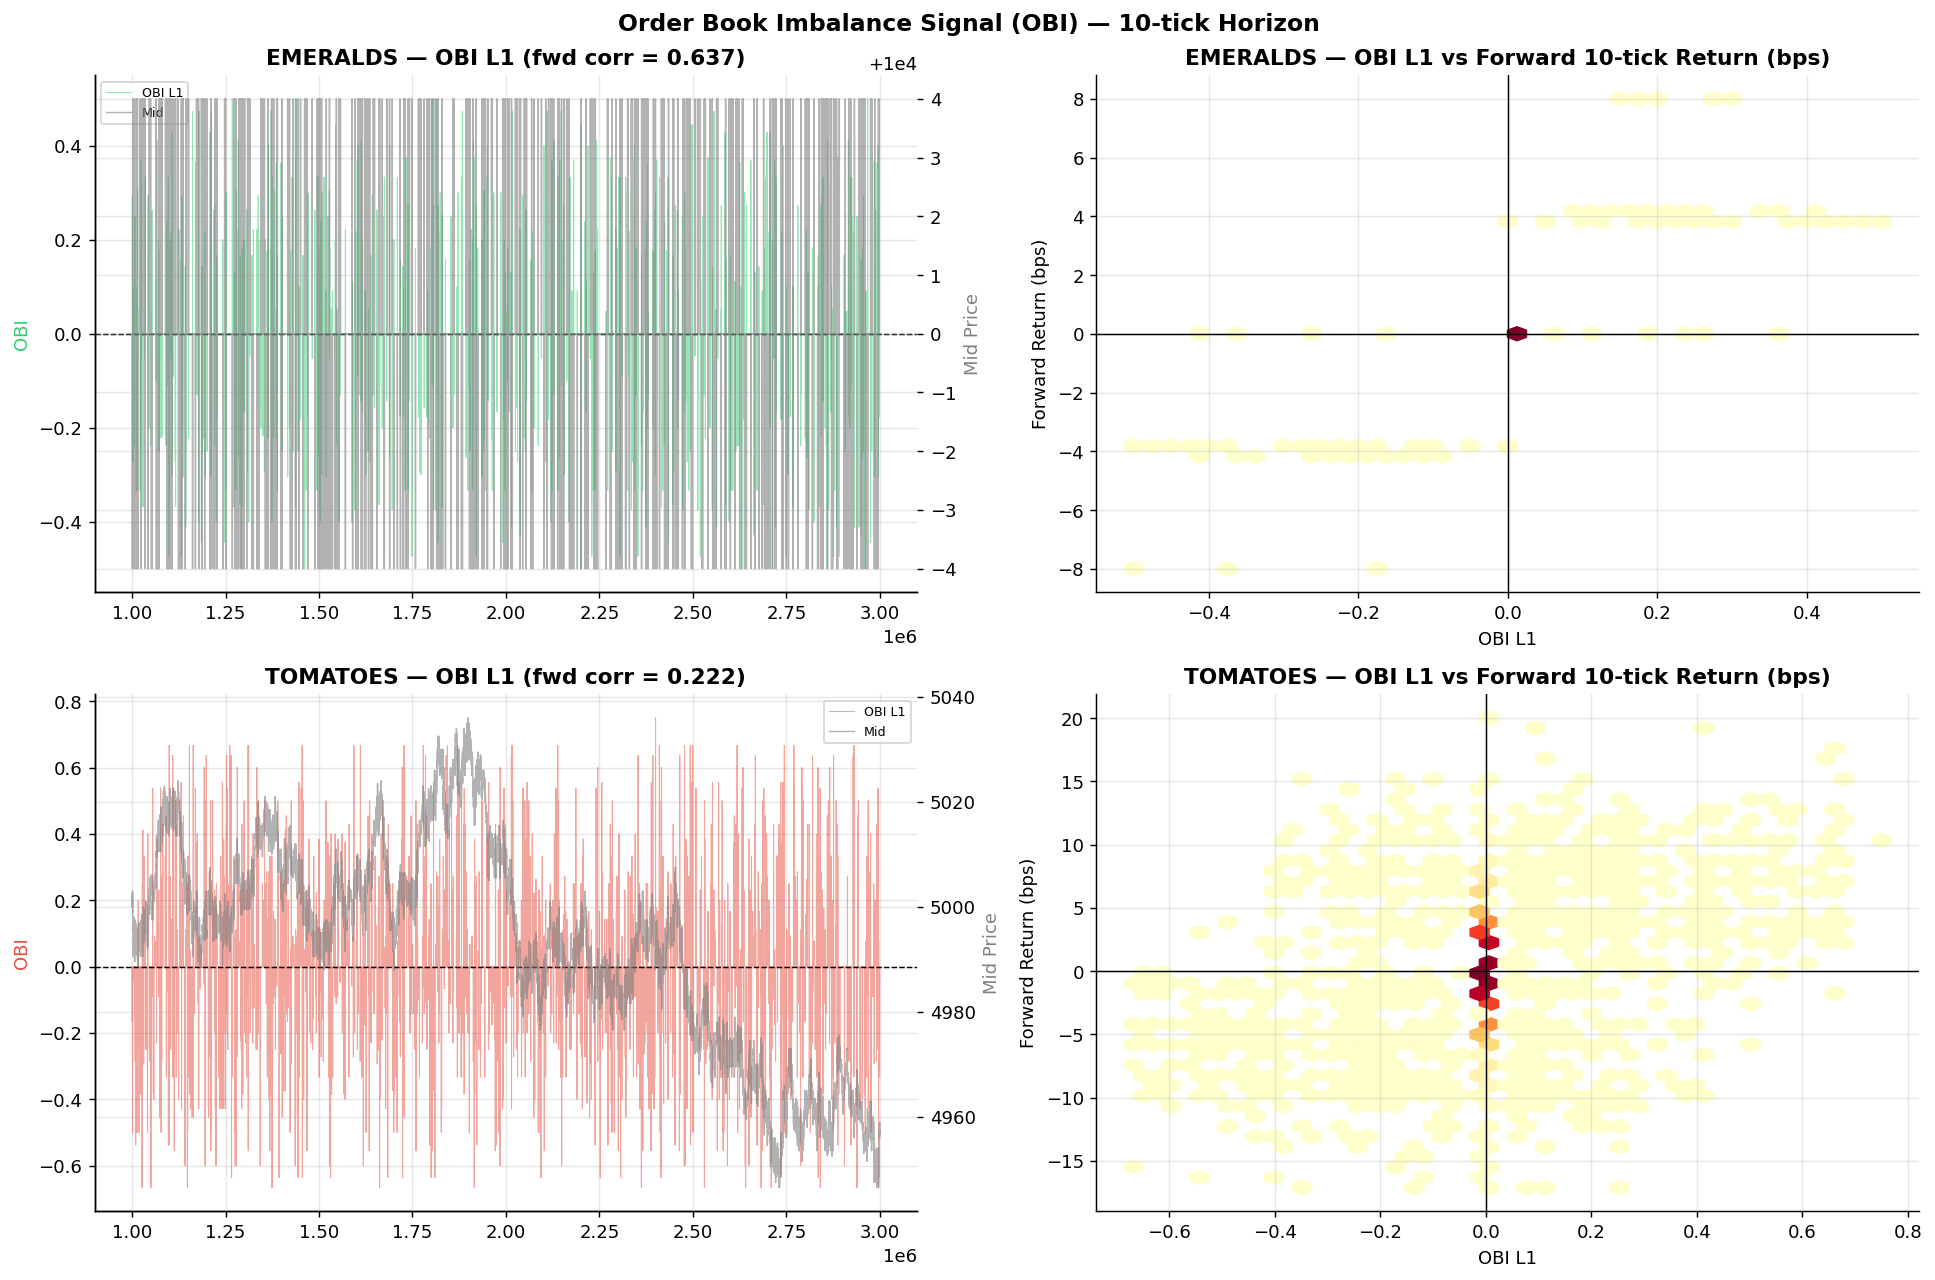

,obi_l1_corr_fwd10t
product,
EMERALDS,0.6370
TOMATOES,0.2223



>> Correlation > 0.05: OBI is a useful directional signal.
>> If hexbin density is higher in the top-right (high OBI → positive return),
   the signal is real — submit limit buys when OBI > 0.5, limit sells when OBI < −0.5.


In [11]:
# ── 5b ORDER BOOK IMBALANCE (OBI) ────────────────────────────────────────────
# OBI = (bid_vol_L1 − ask_vol_L1) / (bid_vol_L1 + ask_vol_L1)
# Range: −1 (fully ask-heavy → price likely drops) to +1 (fully bid-heavy → price likely rises)

FWD_TICKS = 10   # look N ticks ahead to test if OBI predicts future returns

fig, axes = plt.subplots(len(PRODUCTS), 2, figsize=(15, 5*len(PRODUCTS)))
obi_summary = []

for row, prod in enumerate(PRODUCTS):
    sub = prices[prices['product']==prod].copy().sort_values('abs_ts').reset_index(drop=True)

    bv1 = sub['bid_volume_1'].abs()
    av1 = sub['ask_volume_1'].abs()
    total = (bv1 + av1).replace(0, np.nan)
    sub['obi_l1'] = (bv1 - av1) / total

    # Weighted L1+L2
    if 'bid_volume_2' in sub.columns:
        bv2 = sub['bid_volume_2'].abs().fillna(0)
        av2 = sub['ask_volume_2'].abs().fillna(0)
        total2 = (bv1+bv2+av1+av2).replace(0, np.nan)
        sub['obi_l2'] = (bv1+bv2 - av1-av2) / total2

    sub['fwd_ret'] = sub['mid_price'].shift(-FWD_TICKS) / sub['mid_price'] - 1

    corr_l1 = sub[['obi_l1','fwd_ret']].dropna().corr().iloc[0,1]
    obi_summary.append({'product': prod, f'obi_l1_corr_fwd{FWD_TICKS}t': corr_l1})

    # OBI vs mid-price
    ax0 = axes[row][0]
    ax0b = ax0.twinx()
    ax0.plot(sub['abs_ts'], sub['obi_l1'], color=C[prod], alpha=0.5, linewidth=0.6, label='OBI L1')
    ax0b.plot(sub['abs_ts'], sub['mid_price'], color='grey', linewidth=0.8, alpha=0.6, label='Mid')
    ax0.axhline(0, color='black', linestyle='--', linewidth=0.8)
    ax0.set_title(f'{prod} — OBI L1 (fwd corr = {corr_l1:.3f})', fontweight='bold')
    ax0.set_ylabel('OBI', color=C[prod])
    ax0b.set_ylabel('Mid Price', color='grey')
    h1,l1 = ax0.get_legend_handles_labels()
    h2,l2 = ax0b.get_legend_handles_labels()
    ax0.legend(h1+h2, l1+l2, fontsize=7)

    # OBI vs subsequent return scatter
    ax1 = axes[row][1]
    valid = sub[['obi_l1','fwd_ret']].dropna()
    ax1.hexbin(valid['obi_l1'], valid['fwd_ret']*1e4, gridsize=40, cmap='YlOrRd', mincnt=1)
    ax1.axhline(0, color='black', linewidth=0.8)
    ax1.axvline(0, color='black', linewidth=0.8)
    ax1.set_title(f'{prod} — OBI L1 vs Forward {FWD_TICKS}-tick Return (bps)', fontweight='bold')
    ax1.set_xlabel('OBI L1')
    ax1.set_ylabel('Forward Return (bps)')

plt.suptitle(f'Order Book Imbalance Signal (OBI) — {FWD_TICKS}-tick Horizon', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

display(pd.DataFrame(obi_summary).set_index('product').round(4))
print('\n>> Correlation > 0.05: OBI is a useful directional signal.')
print('>> If hexbin density is higher in the top-right (high OBI → positive return),')
print('   the signal is real — submit limit buys when OBI > 0.5, limit sells when OBI < −0.5.')

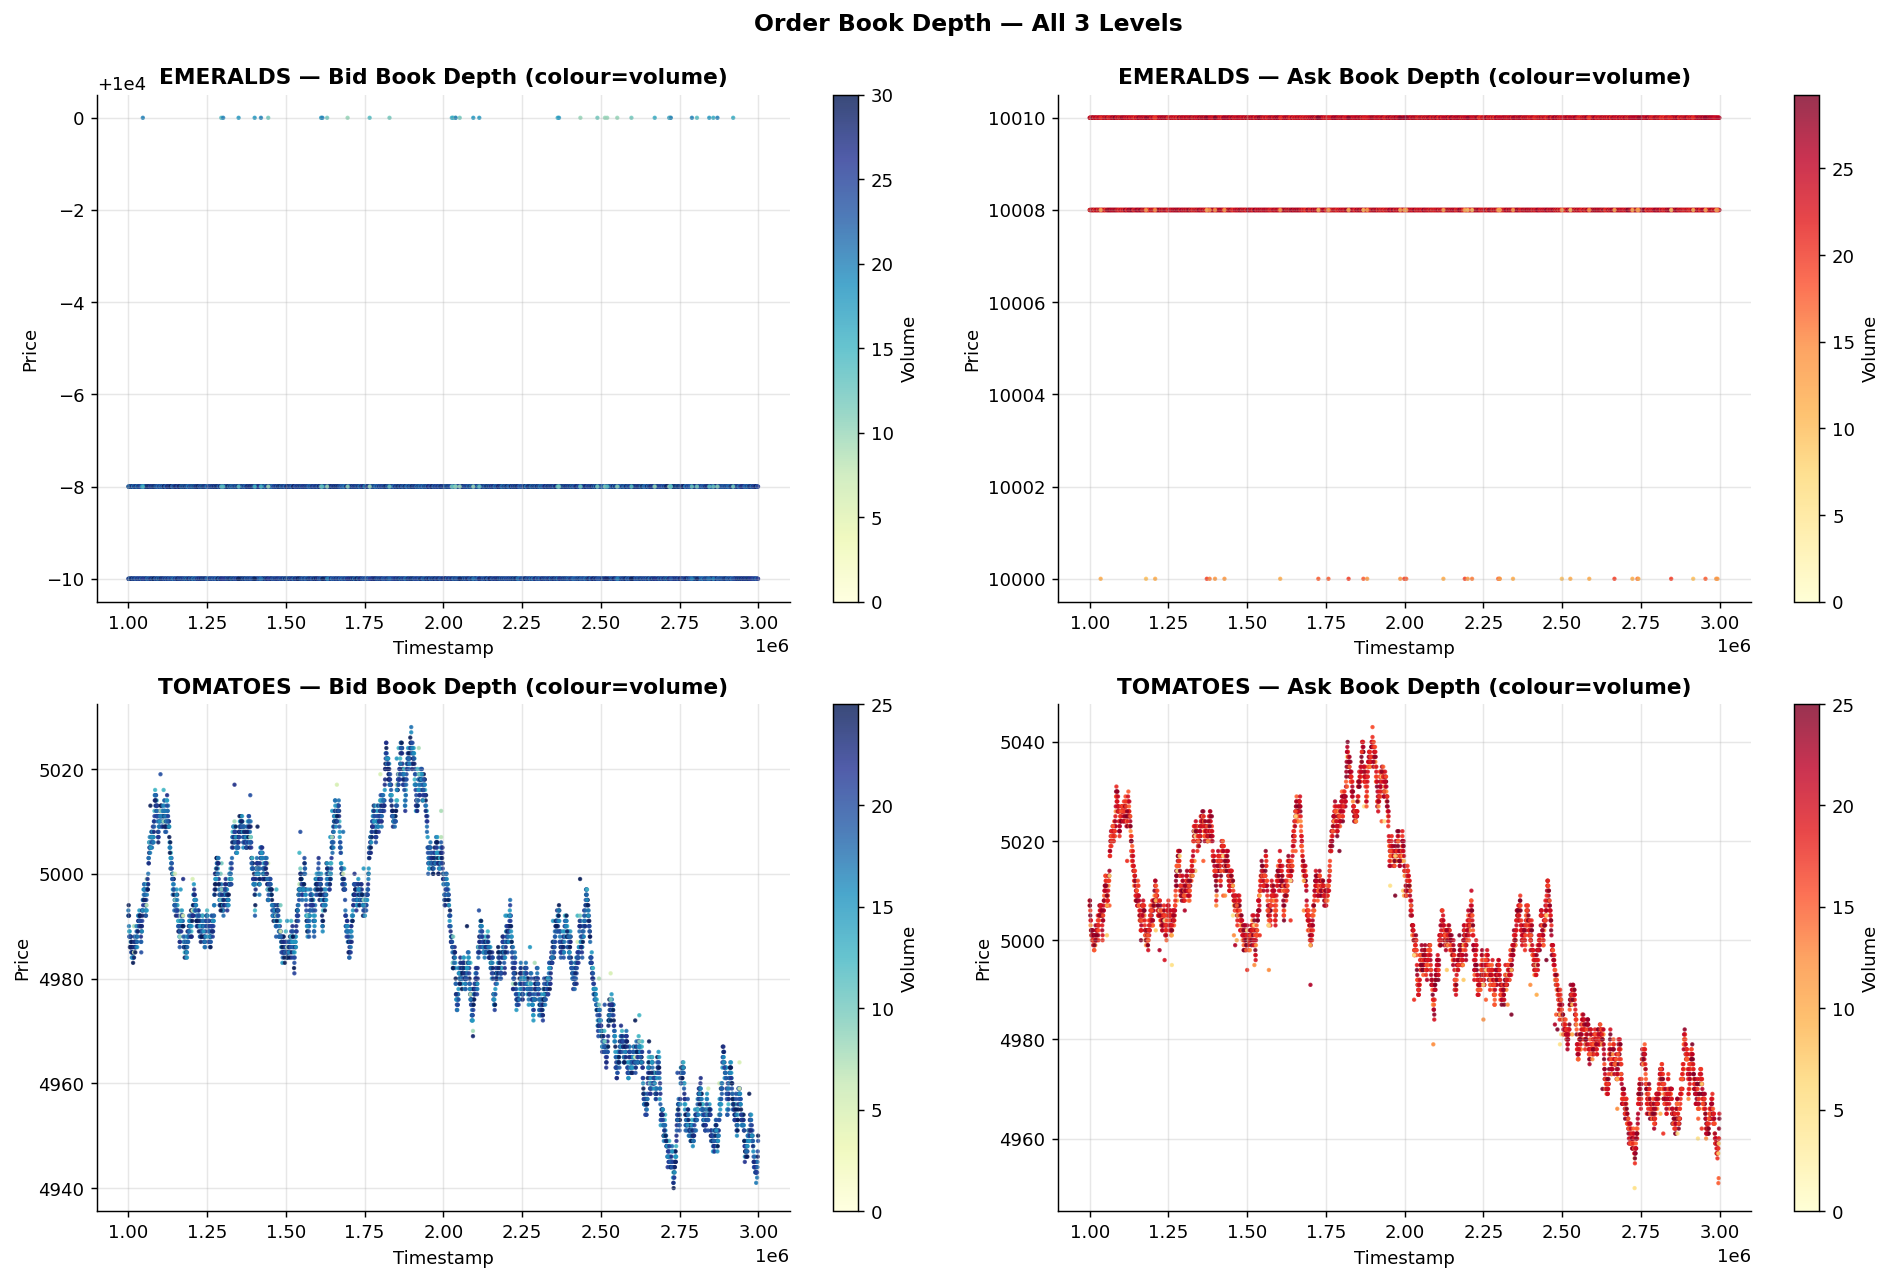

>> Horizontal bright bands = bots always quoting at the same price level.
>> For EMERALDS: expect bands near 9992 and 10008 (the systematic bot quotes).
>> These fixed walls define the true fair-value boundaries — quote inside them.


In [12]:
# ── 5c BOOK DEPTH (all 3 levels) ─────────────────────────────────────────────
# Shows where liquidity pools at each level — large consistent volumes at fixed prices
# indicate systematic bot quoting ("walls")

fig, axes = plt.subplots(len(PRODUCTS), 2, figsize=(15, 5*len(PRODUCTS)))

for row, prod in enumerate(PRODUCTS):
    sub = prices[prices['product']==prod].sort_values('abs_ts')
    # Downsample for plotting speed
    sub_s = sub.iloc[::10]

    for col_idx, side in enumerate(['bid','ask']):
        ax = axes[row][col_idx]
        for lvl in range(1, 4):
            pc = f'{side}_price_{lvl}'
            vc = f'{side}_volume_{lvl}'
            if pc not in sub_s.columns:
                continue
            sc = ax.scatter(sub_s['abs_ts'], sub_s[pc],
                             c=sub_s[vc].abs(),
                             cmap='YlOrRd' if side=='ask' else 'YlGnBu',
                             s=2, alpha=0.8,
                             vmin=0, vmax=sub_s[vc].abs().quantile(0.95))
        plt.colorbar(sc, ax=ax, label='Volume')
        ax.set_title(f'{prod} — {side.capitalize()} Book Depth (colour=volume)', fontweight='bold')
        ax.set_xlabel('Timestamp')
        ax.set_ylabel('Price')

plt.suptitle('Order Book Depth — All 3 Levels', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()
print('>> Horizontal bright bands = bots always quoting at the same price level.')
print('>> For EMERALDS: expect bands near 9992 and 10008 (the systematic bot quotes).')
print('>> These fixed walls define the true fair-value boundaries — quote inside them.')

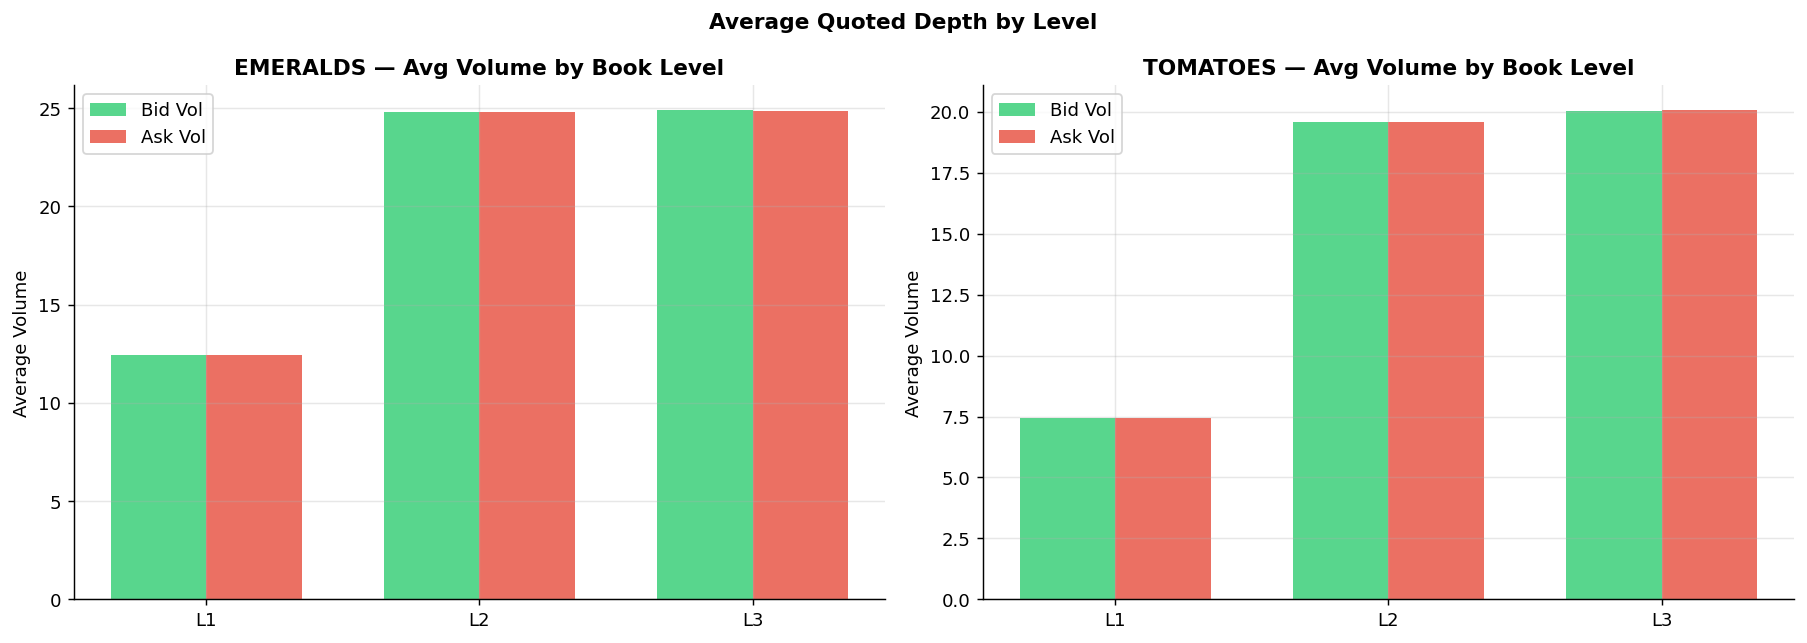

>> L1 (best bid/ask) carries most volume → market depth is concentrated at the touch.
>> If L2/L3 are almost empty, the order book is thin beyond best price — gap risk is high.


In [13]:
# ── 5d QUOTE VOLUME BY LEVEL ──────────────────────────────────────────────────
# Average quoted volume at each book level — where is the market providing depth?

fig, axes = plt.subplots(1, len(PRODUCTS), figsize=(14, 5))
if len(PRODUCTS) == 1: axes = [axes]

for ax, prod in zip(axes, PRODUCTS):
    sub = prices[prices['product']==prod]
    bid_vols = [sub[f'bid_volume_{l}'].abs().mean() for l in range(1,4) if f'bid_volume_{l}' in sub]
    ask_vols = [sub[f'ask_volume_{l}'].abs().mean() for l in range(1,4) if f'ask_volume_{l}' in sub]
    levels = [f'L{l}' for l in range(1, len(bid_vols)+1)]

    x = np.arange(len(levels))
    w = 0.35
    ax.bar(x - w/2, bid_vols, w, label='Bid Vol', color='#2ecc71', alpha=0.8)
    ax.bar(x + w/2, ask_vols, w, label='Ask Vol', color='#e74c3c', alpha=0.8)
    ax.set_xticks(x); ax.set_xticklabels(levels)
    ax.set_title(f'{prod} — Avg Volume by Book Level', fontweight='bold')
    ax.set_ylabel('Average Volume')
    ax.legend()

plt.suptitle('Average Quoted Depth by Level', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()
print('>> L1 (best bid/ask) carries most volume → market depth is concentrated at the touch.')
print('>> If L2/L3 are almost empty, the order book is thin beyond best price — gap risk is high.')

---
## 6 — Stationarity & Mean-Reversion Tests

**Augmented Dickey-Fuller (ADF) test:** tests whether the price series has a unit root (random walk) vs. being stationary (mean-reverting).
- p < 0.05 → stationary → **market-make and mean-revert**
- p ≥ 0.05 → unit root → **trend-follow or pairs trade**

In [14]:
print('=== Augmented Dickey-Fuller Stationarity Test ===')
print(f'{"Product":<14} {"Day":<6} {"ADF Stat":>10} {"p-value":>10} {"Crit 1%":>10} {"Crit 5%":>10} {"Verdict"}')
print('-' * 75)

adf_all = []
for prod in PRODUCTS:
    for day in DAYS:
        sub = prices[(prices['product']==prod) & (prices['source_day']==day)]['mid_price'].dropna()
        stat, p, _, _, crits, _ = adfuller(sub)
        verdict = 'STATIONARY ✓' if p < 0.05 else 'UNIT ROOT  ✗'
        print(f'{prod:<14} {day:<6} {stat:>10.4f} {p:>10.4f} {crits["1%"]:>10.4f} {crits["5%"]:>10.4f} {verdict}')
        adf_all.append({'product':prod,'day':day,'adf_stat':stat,'p_value':p,
                         'stationary':p<0.05,'crit_5pct':crits['5%']})

print('\n>> EMERALDS should be stationary (p < 0.05) — it is designed to be mean-reverting.')
print('>> TOMATOES should NOT be stationary — it drifts, so pure mean-reversion loses money.')

=== Augmented Dickey-Fuller Stationarity Test ===
Product        Day      ADF Stat    p-value    Crit 1%    Crit 5% Verdict
---------------------------------------------------------------------------
EMERALDS       -2       -71.8766     0.0000    -3.4310    -2.8618 STATIONARY ✓
EMERALDS       -1       -97.2206     0.0000    -3.4310    -2.8618 STATIONARY ✓
TOMATOES       -2        -2.3969     0.1426    -3.4310    -2.8618 UNIT ROOT  ✗
TOMATOES       -1        -2.0644     0.2591    -3.4310    -2.8618 UNIT ROOT  ✗

>> EMERALDS should be stationary (p < 0.05) — it is designed to be mean-reverting.
>> TOMATOES should NOT be stationary — it drifts, so pure mean-reversion loses money.


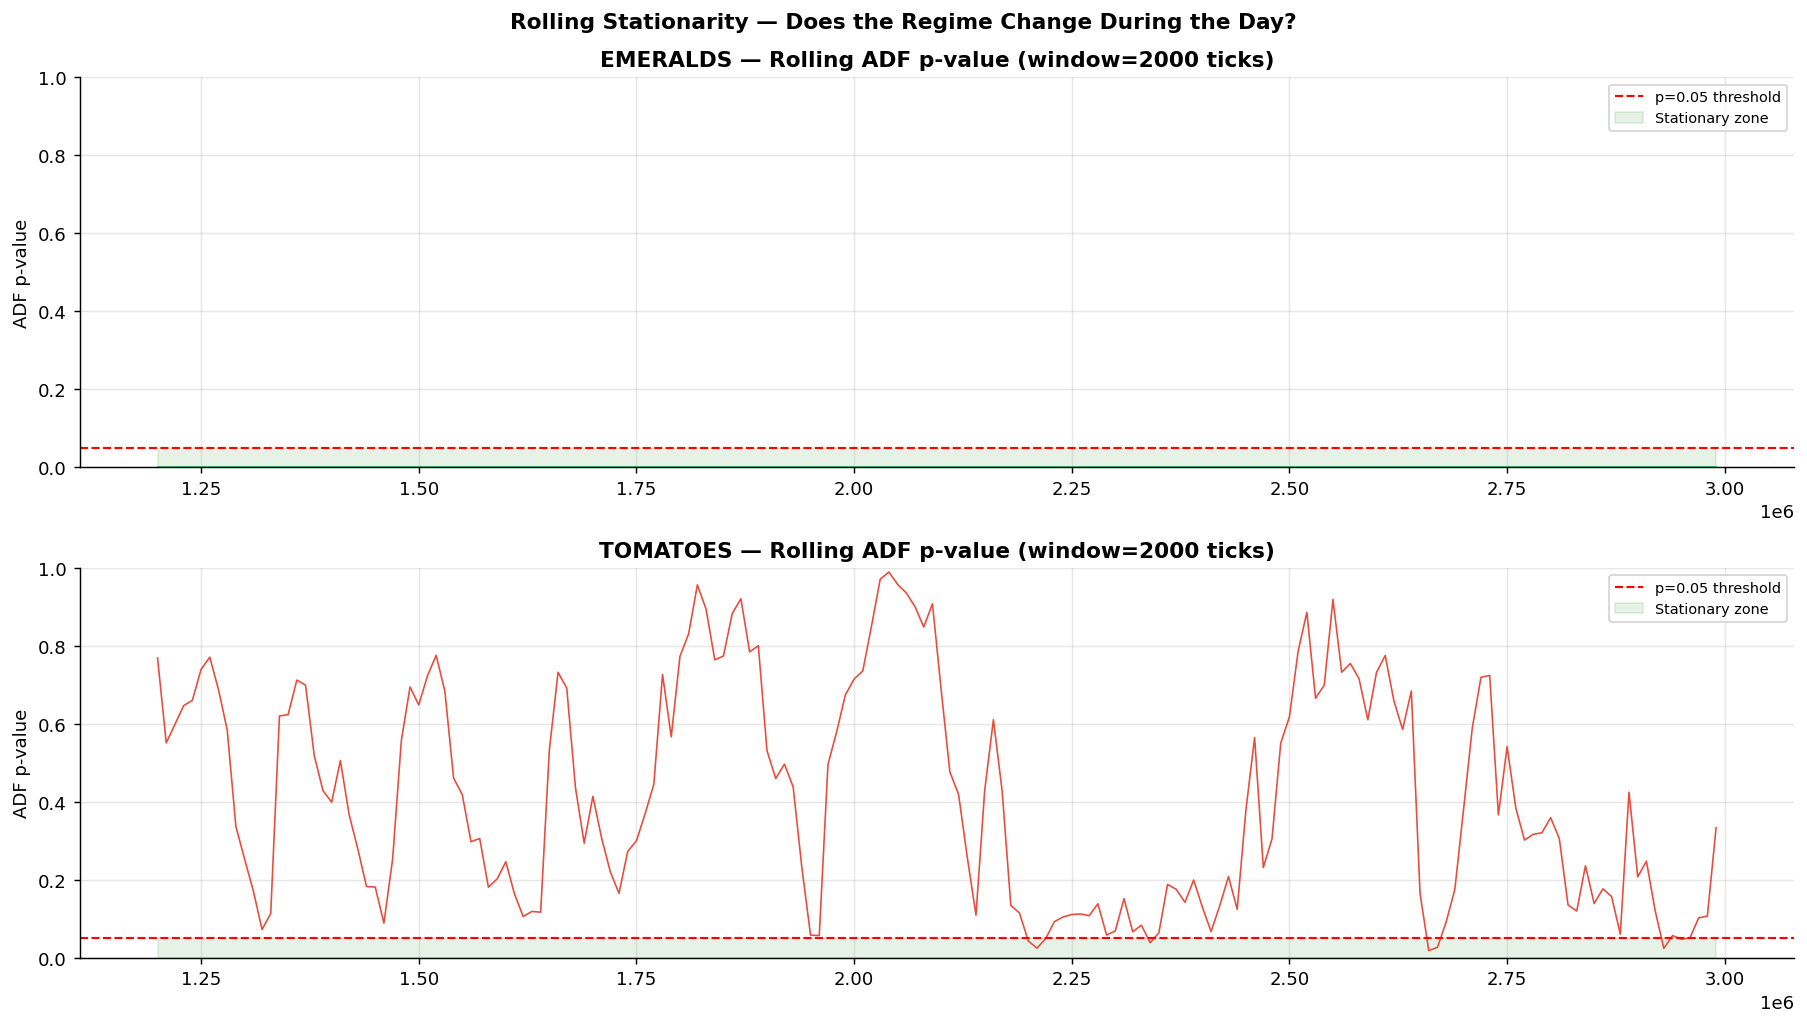

>> Periods when TOMATOES p < 0.05: price paused its trend → mean-revert those windows.
>> Periods when EMERALDS p > 0.05: unusual — something disrupted the equilibrium.


In [15]:
# ── ROLLING ADF (p-value over time) ──────────────────────────────────────────
# Shows whether the stationarity regime is stable or switches mid-day
ROLL_ADF = 2000  # rolling window in ticks

fig, axes = plt.subplots(len(PRODUCTS), 1, figsize=(14, 4*len(PRODUCTS)))
if len(PRODUCTS)==1: axes=[axes]

for ax, prod in zip(axes, PRODUCTS):
    sub = prices[prices['product']==prod].sort_values('abs_ts').reset_index(drop=True)
    p_vals = []
    ts_vals = []
    for i in range(ROLL_ADF, len(sub), 100):
        window = sub['mid_price'].iloc[i-ROLL_ADF:i].dropna()
        try:
            _, pv, *_ = adfuller(window)
            p_vals.append(pv)
            ts_vals.append(sub['abs_ts'].iloc[i])
        except:
            pass

    ax.plot(ts_vals, p_vals, color=C[prod], linewidth=0.9)
    ax.axhline(0.05, color='red', linestyle='--', linewidth=1.2, label='p=0.05 threshold')
    ax.fill_between(ts_vals, 0, 0.05, alpha=0.1, color='green', label='Stationary zone')
    ax.set_title(f'{prod} — Rolling ADF p-value (window={ROLL_ADF} ticks)', fontweight='bold')
    ax.set_ylabel('ADF p-value')
    ax.set_ylim(0, 1)
    ax.legend(fontsize=8)

plt.suptitle('Rolling Stationarity — Does the Regime Change During the Day?', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()
print('>> Periods when TOMATOES p < 0.05: price paused its trend → mean-revert those windows.')
print('>> Periods when EMERALDS p > 0.05: unusual — something disrupted the equilibrium.')

---
## 7 — Return Autocorrelation

**ACF (Autocorrelation Function):** measures how much today's return predicts returns N ticks in the future.
- **Negative lag-1**: price reverses after each tick → market-make aggressively (post tight quotes both sides)
- **Positive lag-1**: price continues in same direction → momentum; don't fade moves
- **Significant lags at 5–20**: predictable patterns at that frequency → trade around them

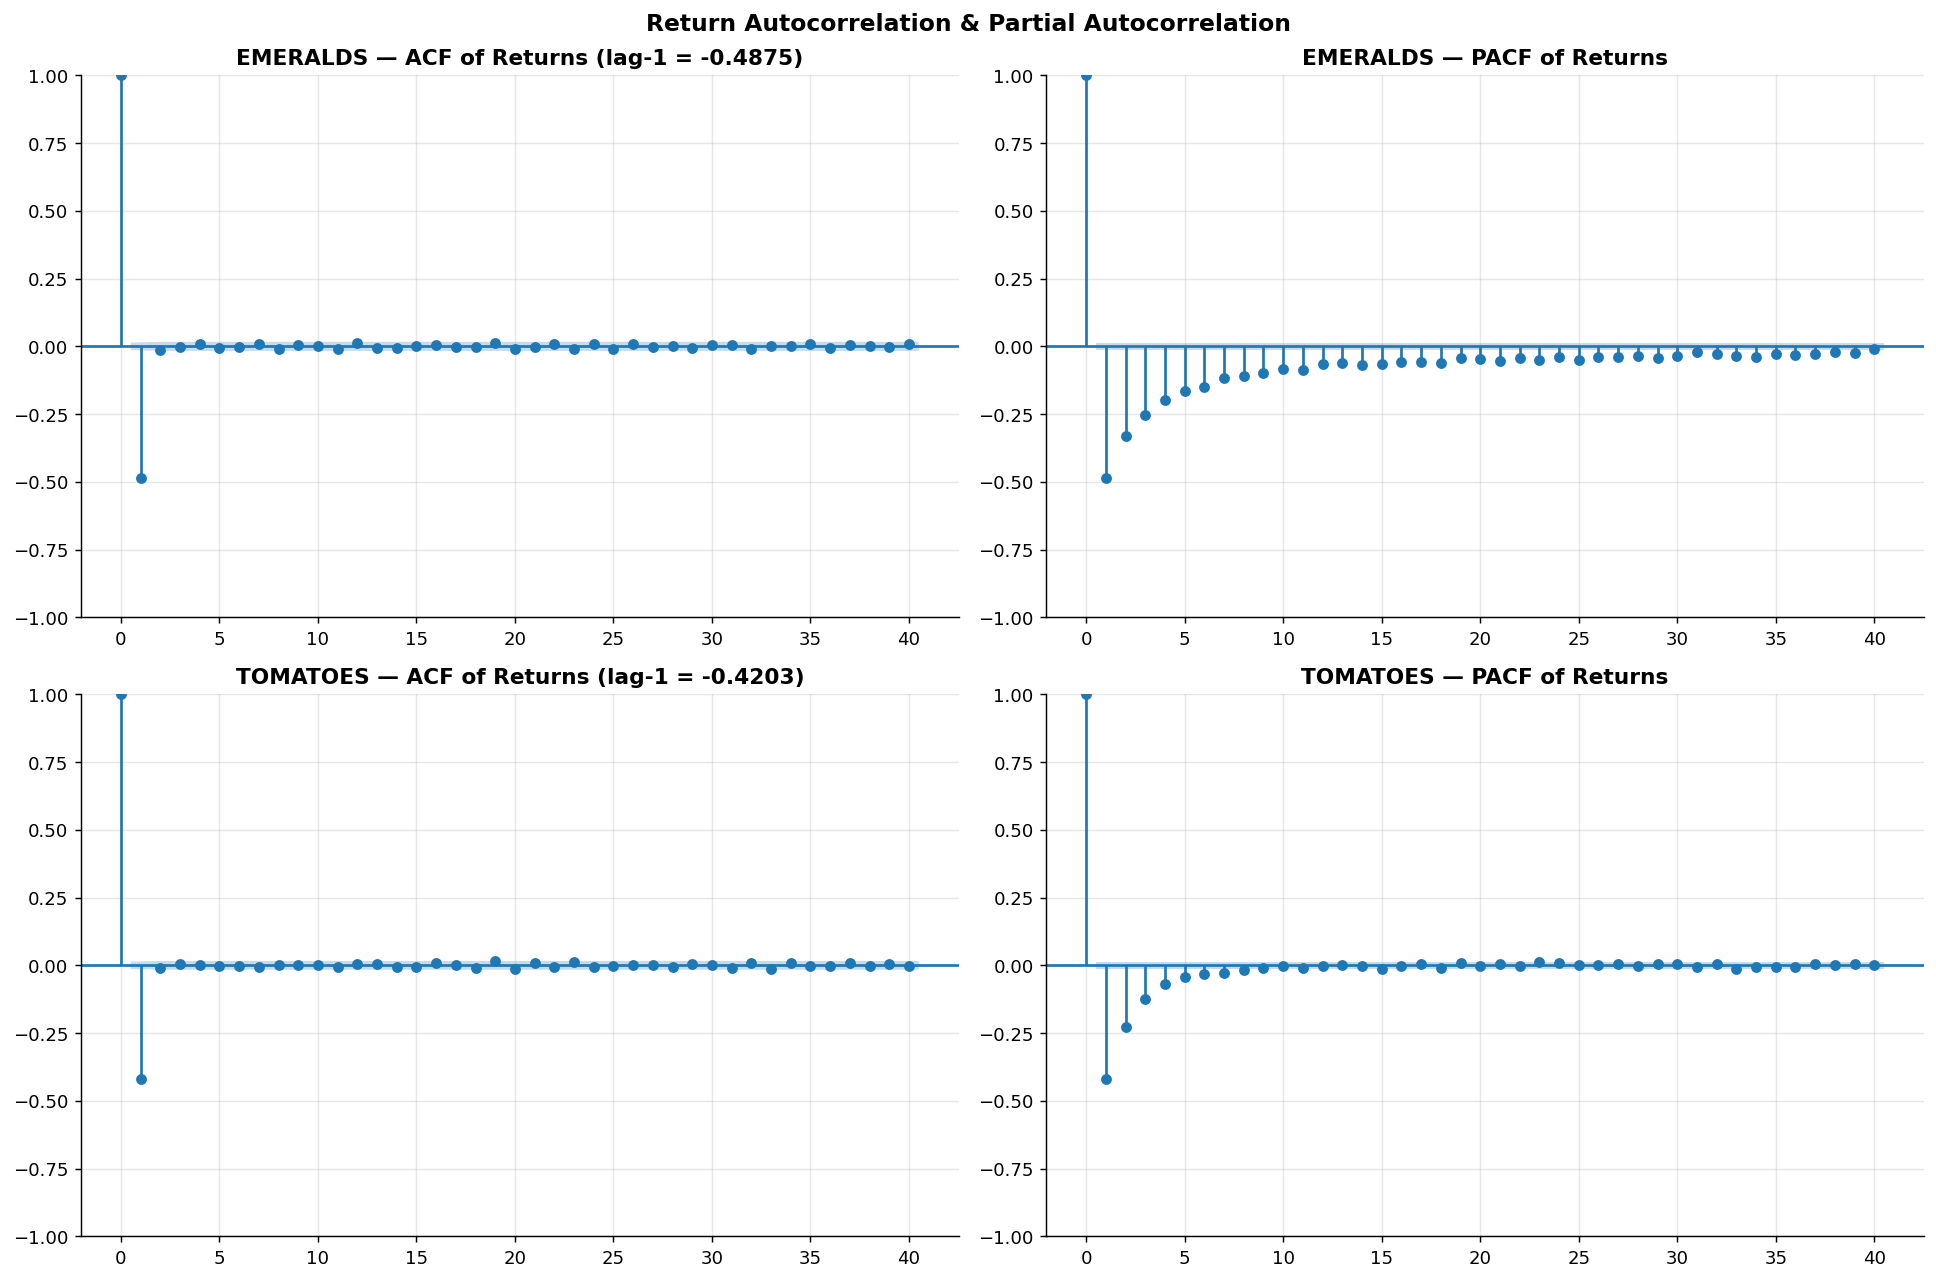

>> Blue bands = 95% confidence interval under null of no autocorrelation.
>> EMERALDS lag-1 < 0: classic microstructure mean-reversion (bid-ask bounce).
>> TOMATOES lag-1 > 0: trend persistence — follow the direction of recent moves.


In [16]:
fig, axes = plt.subplots(len(PRODUCTS), 2, figsize=(15, 5*len(PRODUCTS)))
if len(PRODUCTS)==1: axes=[axes]

for row, prod in enumerate(PRODUCTS):
    sub = prices[prices['product']==prod].sort_values('abs_ts')
    ret = np.log(sub['mid_price'] / sub['mid_price'].shift(1)).dropna()

    lag1 = ret.autocorr(1)

    sm.graphics.tsa.plot_acf(ret,  lags=40, ax=axes[row][0], alpha=0.05)
    axes[row][0].set_title(f'{prod} — ACF of Returns (lag-1 = {lag1:.4f})', fontweight='bold')

    sm.graphics.tsa.plot_pacf(ret, lags=40, ax=axes[row][1], alpha=0.05)
    axes[row][1].set_title(f'{prod} — PACF of Returns', fontweight='bold')

plt.suptitle('Return Autocorrelation & Partial Autocorrelation', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

print('>> Blue bands = 95% confidence interval under null of no autocorrelation.')
print('>> EMERALDS lag-1 < 0: classic microstructure mean-reversion (bid-ask bounce).')
print('>> TOMATOES lag-1 > 0: trend persistence — follow the direction of recent moves.')

=== Directional Accuracy (% of time current return sign matches future sign) ===


,lag_1,lag_2,lag_5,lag_10,lag_20,lag_50
product,,,,,,
EMERALDS,90.62,88.06,87.94,87.98,87.76,87.89
TOMATOES,30.08,33.76,33.28,32.87,33.25,33.67


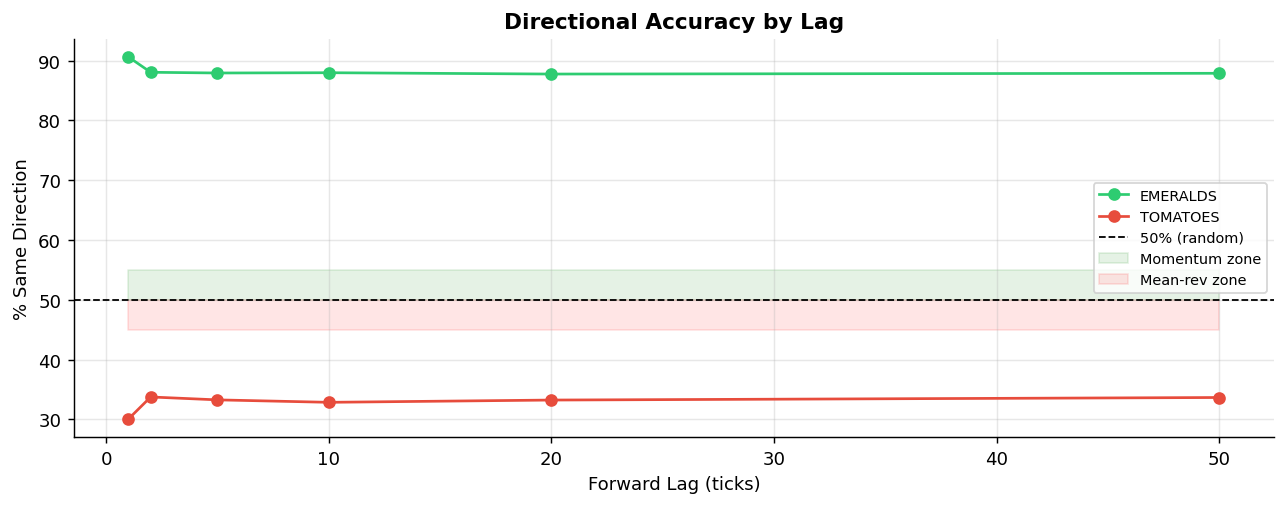


>> < 50%: mean-reversion → after a move up, bet on reversal.
>> > 50%: momentum → after a move up, stay long or add.


In [17]:
# ── DIRECTIONAL ACCURACY TEST ─────────────────────────────────────────────────
# What % of time does sign(ret[t]) predict sign(ret[t+N])?
# > 50%: momentum signal. < 50%: mean-reversion signal.

lags_test = [1, 2, 5, 10, 20, 50]
dir_results = []

for prod in PRODUCTS:
    sub = prices[prices['product']==prod].sort_values('abs_ts')
    ret = np.log(sub['mid_price'] / sub['mid_price'].shift(1))
    row = {'product': prod}
    for lag in lags_test:
        fwd = ret.shift(-lag)
        same_dir = np.sign(ret) == np.sign(fwd)
        row[f'lag_{lag}'] = same_dir.dropna().mean() * 100
    dir_results.append(row)

dir_df = pd.DataFrame(dir_results).set_index('product')
print('=== Directional Accuracy (% of time current return sign matches future sign) ===')
display(dir_df.round(2))

# Visualise
fig, ax = plt.subplots(figsize=(10, 4))
for prod in PRODUCTS:
    vals = dir_df.loc[prod].values
    ax.plot(lags_test, vals, marker='o', color=C[prod], label=prod, linewidth=1.5)
ax.axhline(50, color='black', linestyle='--', linewidth=1, label='50% (random)')
ax.fill_between(lags_test, 50, 55, alpha=0.1, color='green', label='Momentum zone')
ax.fill_between(lags_test, 45, 50, alpha=0.1, color='red',   label='Mean-rev zone')
ax.set_title('Directional Accuracy by Lag', fontweight='bold')
ax.set_xlabel('Forward Lag (ticks)')
ax.set_ylabel('% Same Direction')
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()
print('\n>> < 50%: mean-reversion → after a move up, bet on reversal.')
print('>> > 50%: momentum → after a move up, stay long or add.')

---
## 8 — Half-Life of Mean Reversion

Fit an Ornstein-Uhlenbeck process: Δprice = λ(μ − price) + ε  
Half-life = −ln(2)/λ tells you **how many ticks** until a displaced price returns halfway to its mean.

- Half-life **10–50 ticks** → very fast; tight market-making with quick order cycling  
- Half-life **200–1000 ticks** → swing trade; hold for seconds  
- Half-life **∞** → no mean reversion; do NOT use this strategy

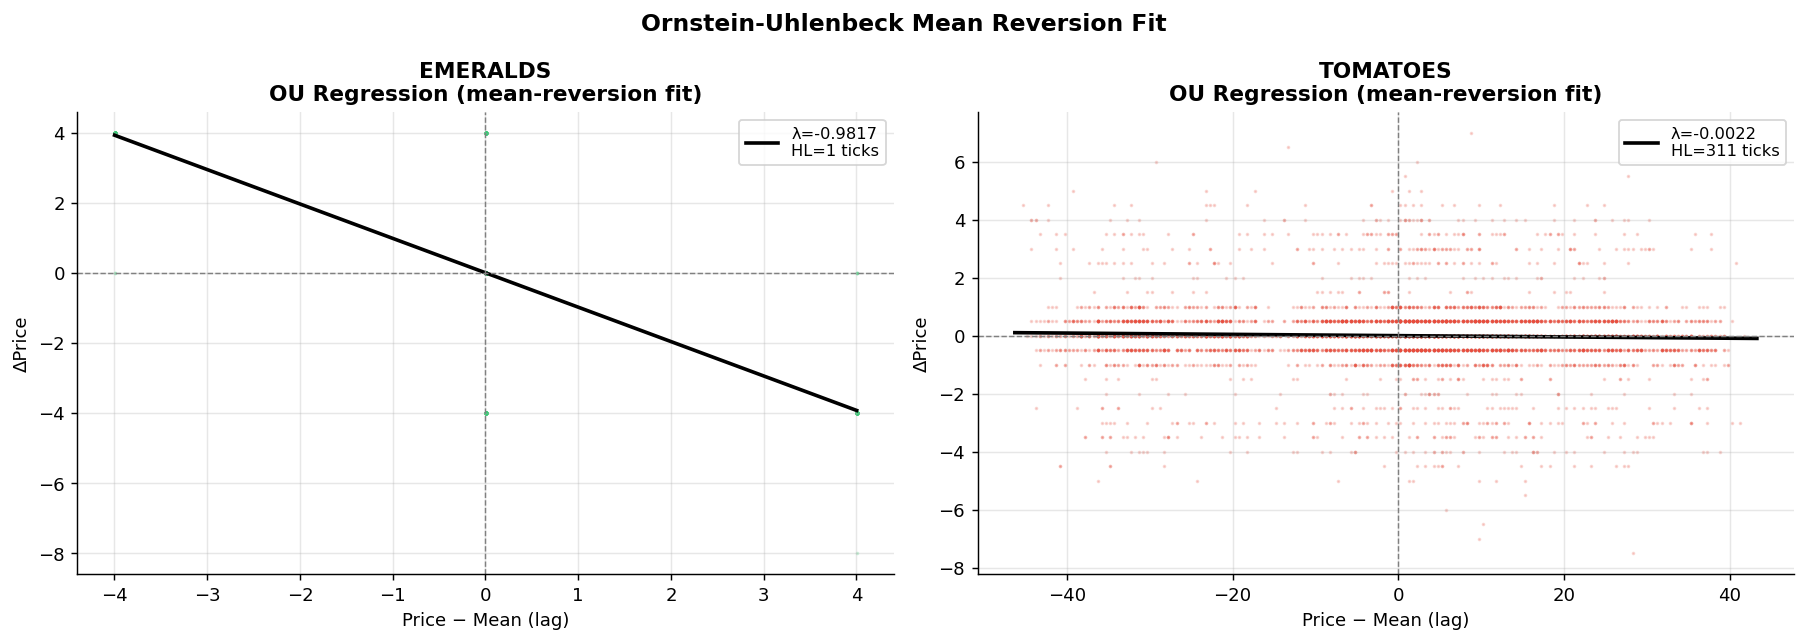

,lambda,half_life_ticks,half_life_sec,r2
product,,,,
EMERALDS,-0.9817,0.7061,0.0706,0.4908
TOMATOES,-0.0022,311.1693,31.1169,0.0011



>> Negative slope in scatter = mean-reverting (price displacement gets corrected).
>> For EMERALDS: expect short half-life → place orders with 1-tick improvement on best quote.
>> For TOMATOES: expect infinite or very long half-life → do NOT mean-revert.


In [18]:
fig, axes = plt.subplots(1, len(PRODUCTS), figsize=(14, 5))
hl_results = []

for ax, prod in zip(axes, PRODUCTS):
    sub = prices[prices['product']==prod].sort_values('abs_ts')
    price_arr = sub['mid_price'].dropna().values

    delta_p = np.diff(price_arr)
    lag_p   = price_arr[:-1] - price_arr[:-1].mean()
    X       = sm.add_constant(lag_p)
    res     = sm.OLS(delta_p, X).fit()
    lam     = res.params[1]
    hl      = -np.log(2) / lam if lam < 0 else np.inf

    hl_results.append({'product':prod, 'lambda':lam, 'half_life_ticks':hl,
                        'half_life_sec': hl*0.1 if np.isfinite(hl) else np.inf,
                        'r2': res.rsquared})

    # Scatter: Δprice vs lag price deviation
    sample_idx = np.random.choice(len(lag_p), size=min(5000, len(lag_p)), replace=False)
    ax.scatter(lag_p[sample_idx], delta_p[sample_idx], s=1, alpha=0.2, color=C[prod])
    x_line = np.linspace(lag_p.min(), lag_p.max(), 100)
    ax.plot(x_line, res.params[0] + lam*x_line, 'k-', linewidth=2,
            label=f'λ={lam:.4f}\nHL={hl:.0f} ticks' if np.isfinite(hl) else f'λ={lam:.4f}\nHL=∞')
    ax.axhline(0, color='grey', linestyle='--', linewidth=0.8)
    ax.axvline(0, color='grey', linestyle='--', linewidth=0.8)
    ax.set_title(f'{prod}\nOU Regression (mean-reversion fit)', fontweight='bold')
    ax.set_xlabel('Price − Mean (lag)')
    ax.set_ylabel('ΔPrice')
    ax.legend(fontsize=9)

plt.suptitle('Ornstein-Uhlenbeck Mean Reversion Fit', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

hl_df = pd.DataFrame(hl_results).set_index('product')
display(hl_df.round(4))
print('\n>> Negative slope in scatter = mean-reverting (price displacement gets corrected).')
print('>> For EMERALDS: expect short half-life → place orders with 1-tick improvement on best quote.')
print('>> For TOMATOES: expect infinite or very long half-life → do NOT mean-revert.')

---
## 9 — Market Trades Flow Analysis

Public market trades reveal which prices are being lifted and hit, and by whom. Since buyer/seller are blank in this round (anonymous), we focus on **trade size patterns**, **timing**, and **price relative to the book**.

=== Trade Summary ===


,total_trades,total_volume,avg_size,price_mean,price_std
symbol,,,,,
EMERALDS,399,2189,5.49,9999.80,7.90
TOMATOES,820,2853,3.48,4992.57,21.13


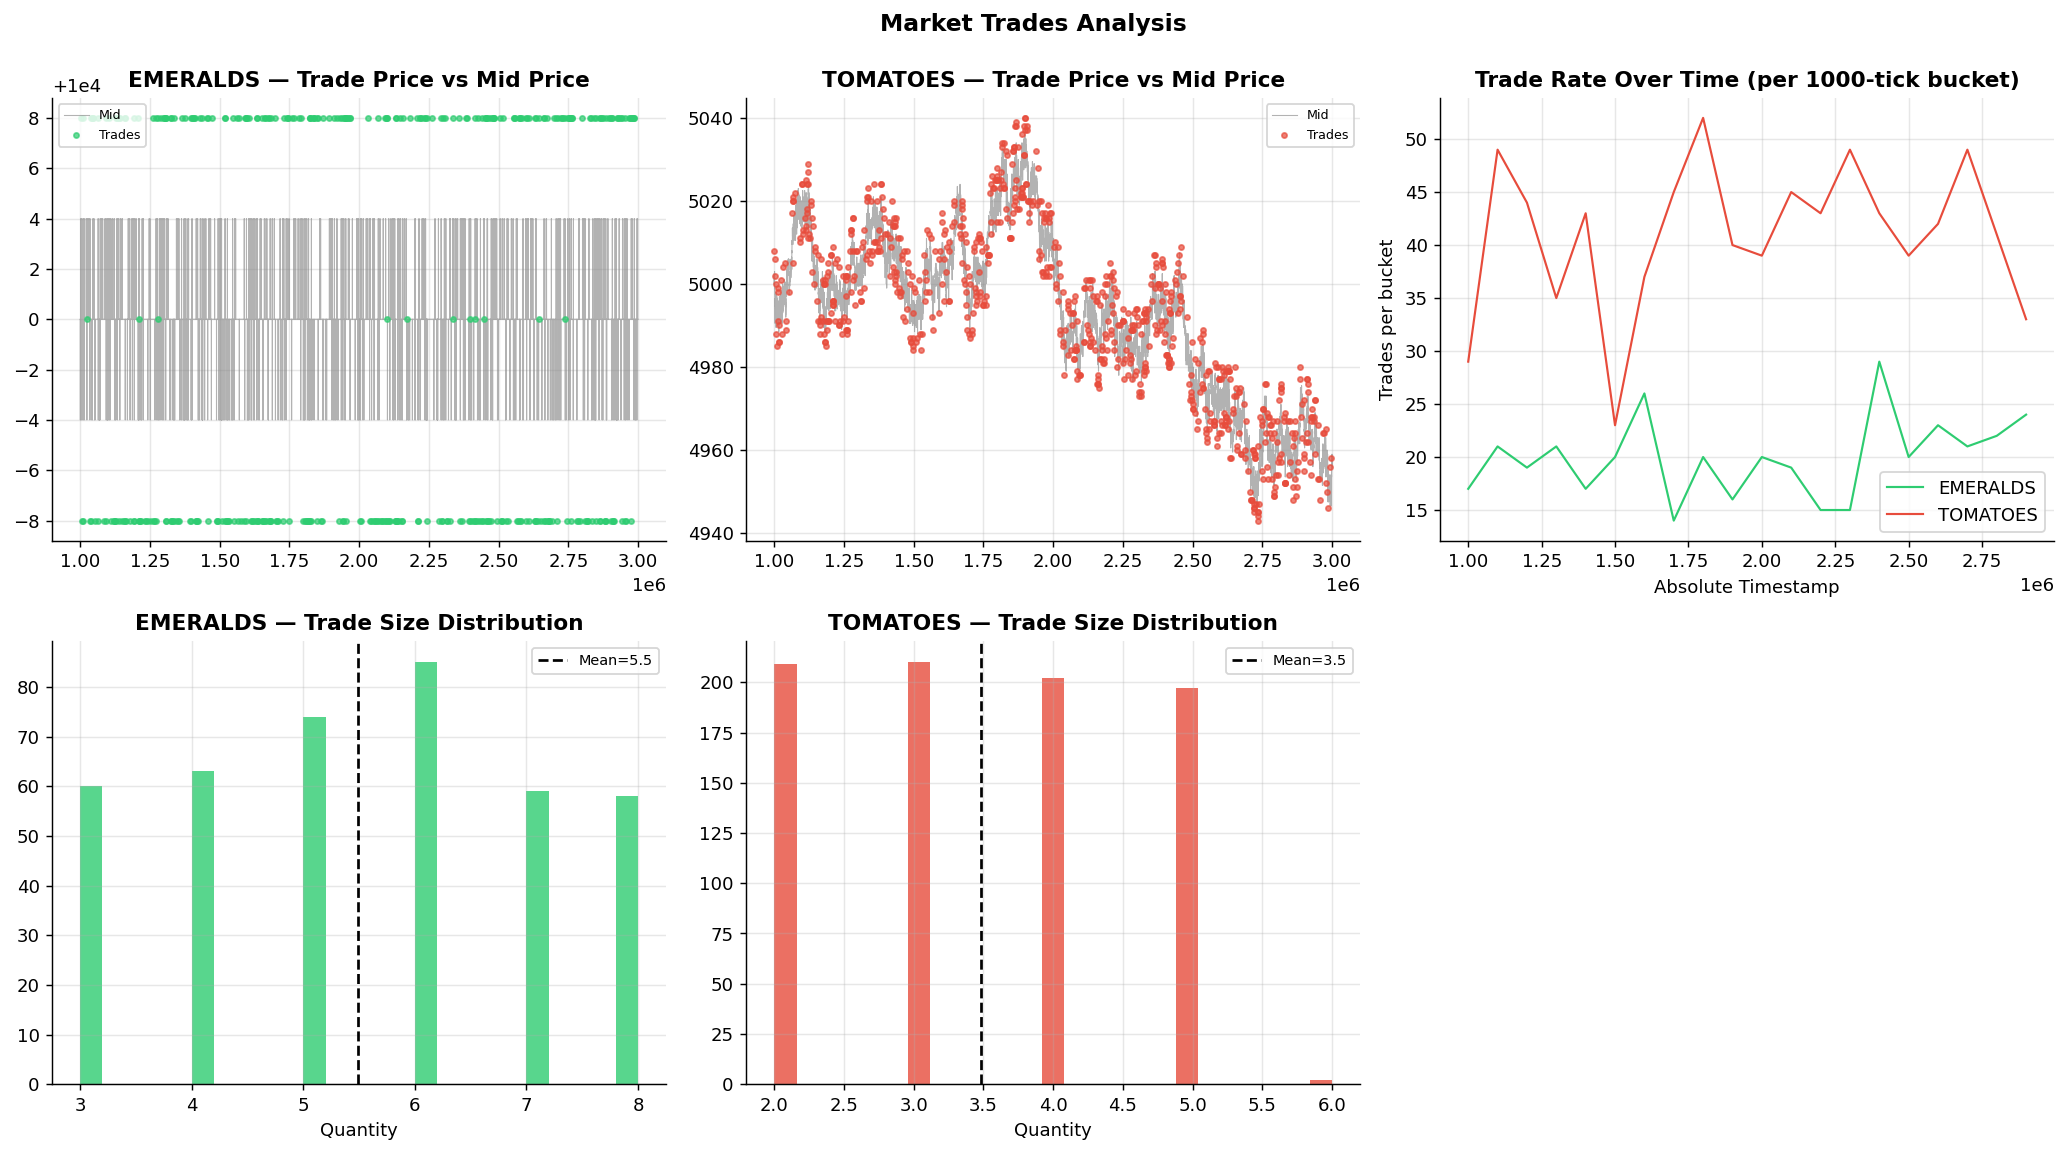

>> Trade price above mid → aggressive buyer (taker); below mid → aggressive seller.
>> Consistent trade sizes (all same value) = bot with fixed lot size → predictable!
>> Trade rate bursts: high activity periods may correspond to bot events.


In [19]:
symbol_col = 'symbol' if 'symbol' in trades.columns else 'product'

# Overview
t_summary = trades.groupby(symbol_col).agg(
    total_trades = ('price','count'),
    total_volume = ('quantity','sum'),
    avg_size     = ('quantity','mean'),
    price_mean   = ('price','mean'),
    price_std    = ('price','std'),
).round(2)
print('=== Trade Summary ===')
display(t_summary)

fig, axes = plt.subplots(2, 3, figsize=(16, 9))

for col, prod in enumerate(PRODUCTS):
    t_prod = trades[trades[symbol_col]==prod].copy()
    p_prod = prices[prices['product']==prod].sort_values('abs_ts')

    # Trade price on mid-price background
    ax0 = axes[0][col]
    ax0.plot(p_prod['abs_ts'], p_prod['mid_price'], color='grey', linewidth=0.6, alpha=0.6, label='Mid')
    ax0.scatter(t_prod['abs_ts'], t_prod['price'], color=C[prod], s=8,
                zorder=5, alpha=0.7, label='Trades')
    ax0.set_title(f'{prod} — Trade Price vs Mid Price', fontweight='bold')
    ax0.legend(fontsize=7)

    # Trade size distribution
    ax1 = axes[1][col]
    ax1.hist(t_prod['quantity'].abs(), bins=25, color=C[prod], alpha=0.8)
    ax1.axvline(t_prod['quantity'].abs().mean(), color='black', linestyle='--',
                label=f'Mean={t_prod["quantity"].abs().mean():.1f}')
    ax1.set_title(f'{prod} — Trade Size Distribution', fontweight='bold')
    ax1.set_xlabel('Quantity')
    ax1.legend(fontsize=8)

# Trade rate over time (combined)
ax2 = axes[0][2]
for prod in PRODUCTS:
    t_prod = trades[trades[symbol_col]==prod].sort_values('abs_ts')
    # Rolling trade count per 1000-tick window
    t_prod['bucket'] = (t_prod['abs_ts'] // 100_000) * 100_000
    rate = t_prod.groupby('bucket').size()
    ax2.plot(rate.index, rate.values, color=C[prod], label=prod, linewidth=1.2)
ax2.set_title('Trade Rate Over Time (per 1000-tick bucket)', fontweight='bold')
ax2.set_xlabel('Absolute Timestamp')
ax2.set_ylabel('Trades per bucket')
ax2.legend()

axes[1][2].set_visible(False)

plt.suptitle('Market Trades Analysis', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()
print('>> Trade price above mid → aggressive buyer (taker); below mid → aggressive seller.')
print('>> Consistent trade sizes (all same value) = bot with fixed lot size → predictable!')
print('>> Trade rate bursts: high activity periods may correspond to bot events.')


EMERALDS — Aggressor Classification:
aggressor
SELL (hit bid)    204
BUY (lift ask)    195


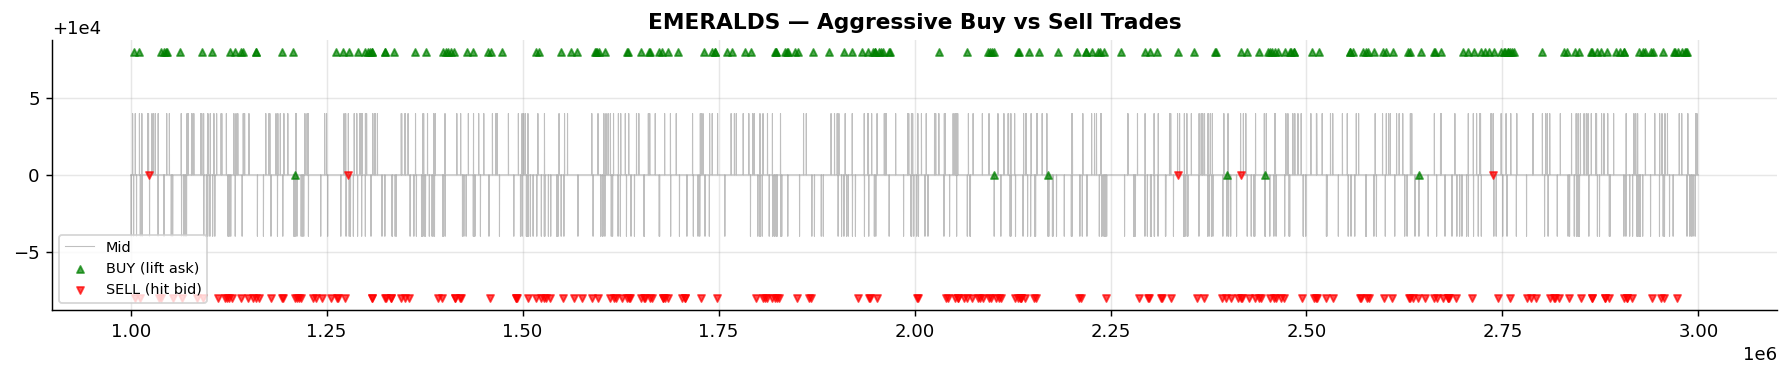


TOMATOES — Aggressor Classification:
aggressor
SELL (hit bid)    433
BUY (lift ask)    387


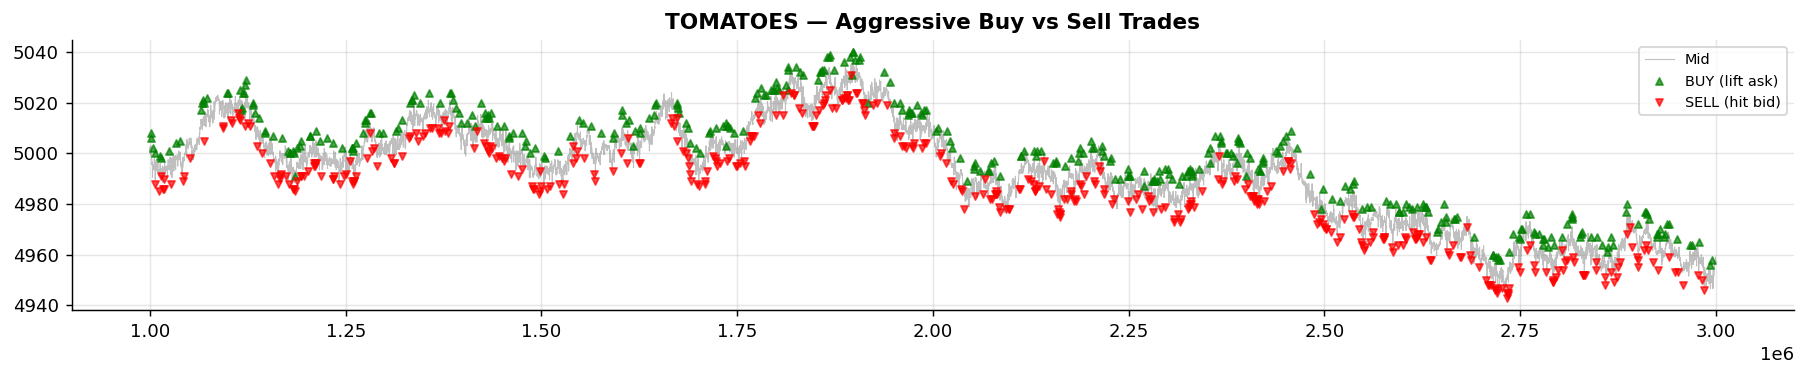


>> More buy aggression in up-trends, sell aggression in down-trends — confirms direction.
>> If buys/sells alternate randomly, there is no directional conviction → pure MM territory.


In [20]:
# ── TRADE PRICE RELATIVE TO BEST BID/ASK ────────────────────────────────────
# Was the trade an aggressor (crossing spread) or a passive fill?

for prod in PRODUCTS:
    t_prod = trades[trades[symbol_col]==prod].sort_values('abs_ts').copy()
    p_prod = prices[prices['product']==prod].sort_values('abs_ts')

    # Merge closest book snapshot to each trade
    merged = pd.merge_asof(t_prod, p_prod[['abs_ts','bid_price_1','ask_price_1','mid_price']],
                            on='abs_ts', direction='backward')

    # Classify aggressor direction
    merged['aggressor'] = 'unknown'
    merged.loc[merged['price'] >= merged['ask_price_1'], 'aggressor'] = 'BUY (lift ask)'
    merged.loc[merged['price'] <= merged['bid_price_1'], 'aggressor'] = 'SELL (hit bid)'

    dist = merged['aggressor'].value_counts()
    print(f'\n{prod} — Aggressor Classification:')
    print(dist.to_string())

    # Visualise aggressor direction
    fig, ax = plt.subplots(figsize=(14, 3))
    ax.plot(p_prod['abs_ts'], p_prod['mid_price'], color='grey', linewidth=0.6, alpha=0.5, label='Mid')
    for agg, color, marker in [('BUY (lift ask)','green','^'), ('SELL (hit bid)','red','v')]:
        sub_agg = merged[merged['aggressor']==agg]
        ax.scatter(sub_agg['abs_ts'], sub_agg['price'], color=color, s=15,
                   marker=marker, alpha=0.7, label=agg, zorder=5)
    ax.set_title(f'{prod} — Aggressive Buy vs Sell Trades', fontweight='bold')
    ax.legend(fontsize=8)
    plt.tight_layout()
    plt.show()

print('\n>> More buy aggression in up-trends, sell aggression in down-trends — confirms direction.')
print('>> If buys/sells alternate randomly, there is no directional conviction → pure MM territory.')

---
## 10 — Cross-Product Correlation & Lead-Lag

Even though EMERALDS and TOMATOES are different markets, understanding whether they influence each other is useful. In Round 2, new products are likely to have basket or index relationships — this analysis trains your eye on what those look like.

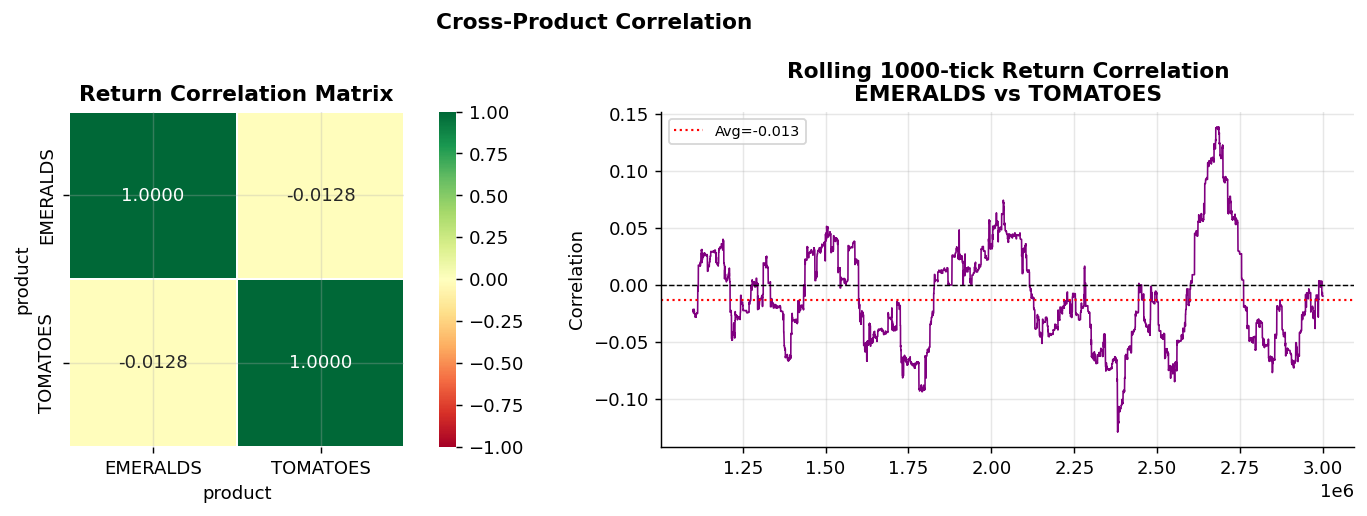

>> Low correlation expected: EMERALDS is stationary, TOMATOES trends → very different risk factors.
>> Spikes in rolling correlation: when correlation briefly appears, market conditions changed.


In [21]:
# ── RETURN CORRELATION HEATMAP ────────────────────────────────────────────────
pivot = prices.pivot_table(index='abs_ts', columns='product', values='mid_price', aggfunc='last')
ret_pivot = np.log(pivot / pivot.shift(1)).dropna()

corr = ret_pivot.corr()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

sns.heatmap(corr, annot=True, fmt='.4f', cmap='RdYlGn', center=0, ax=ax1,
            linewidths=1, vmin=-1, vmax=1, square=True)
ax1.set_title('Return Correlation Matrix', fontweight='bold')

# Rolling 1000-tick correlation
roll_corr = ret_pivot['EMERALDS'].rolling(1000).corr(ret_pivot['TOMATOES'])
ax2.plot(ret_pivot.index, roll_corr, color='purple', linewidth=0.9)
ax2.axhline(0, color='black', linestyle='--', linewidth=0.8)
ax2.axhline(corr.iloc[0,1], color='red', linestyle=':', linewidth=1.2, label=f'Avg={corr.iloc[0,1]:.3f}')
ax2.set_title('Rolling 1000-tick Return Correlation\nEMERALDS vs TOMATOES', fontweight='bold')
ax2.set_ylabel('Correlation')
ax2.legend(fontsize=8)

plt.suptitle('Cross-Product Correlation', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()
print('>> Low correlation expected: EMERALDS is stationary, TOMATOES trends → very different risk factors.')
print('>> Spikes in rolling correlation: when correlation briefly appears, market conditions changed.')

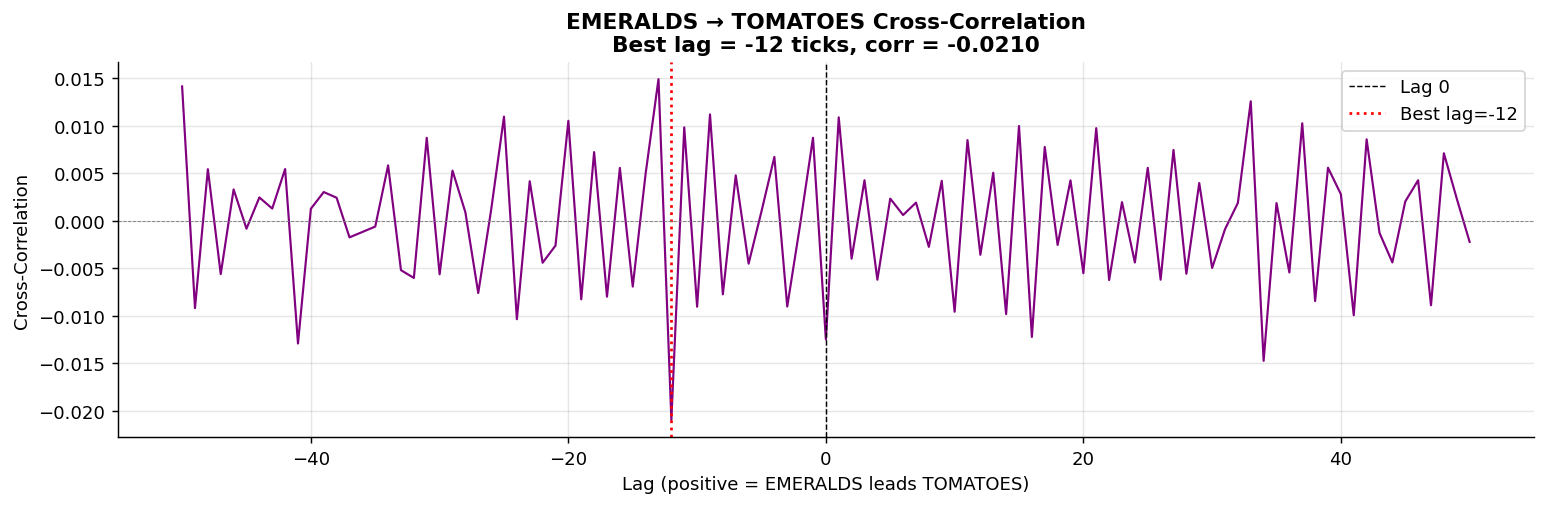

>> Best lag = -12, corr = -0.0210
>> If |best_corr| < 0.03: no meaningful lead-lag → products are independent. (Expected here.)
>> For Round 2 products: replicate this for basket components vs. basket — expect strong lead-lag!


In [22]:
# ── CROSS-CORRELATION AT LAGS ─────────────────────────────────────────────────
# Does EMERALDS predict TOMATOES (or vice versa) N ticks later?
MAX_LAG = 50

r_em = ret_pivot['EMERALDS'].values
r_to = ret_pivot['TOMATOES'].values
lags = range(-MAX_LAG, MAX_LAG+1)

xcorr = [np.corrcoef(r_em[MAX_LAG:-MAX_LAG], r_to[MAX_LAG+lag:len(r_to)-MAX_LAG+lag])[0,1]
          for lag in lags]

best_lag  = list(lags)[np.argmax(np.abs(xcorr))]
best_corr = xcorr[np.argmax(np.abs(xcorr))]

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(list(lags), xcorr, linewidth=1.2, color='purple')
ax.axvline(0,        color='black',  linestyle='--', linewidth=0.8, label='Lag 0')
ax.axvline(best_lag, color='red',    linestyle=':',  linewidth=1.5, label=f'Best lag={best_lag}')
ax.axhline(0,        color='grey',   linestyle='--', linewidth=0.5)
ax.set_title(f'EMERALDS → TOMATOES Cross-Correlation\nBest lag = {best_lag} ticks, corr = {best_corr:.4f}',
             fontweight='bold')
ax.set_xlabel('Lag (positive = EMERALDS leads TOMATOES)')
ax.set_ylabel('Cross-Correlation')
ax.legend()
plt.tight_layout()
plt.show()
print(f'>> Best lag = {best_lag}, corr = {best_corr:.4f}')
print('>> If |best_corr| < 0.03: no meaningful lead-lag → products are independent. (Expected here.)')
print('>> For Round 2 products: replicate this for basket components vs. basket — expect strong lead-lag!')

---
## 11 — Day-over-Day Consistency

Are Day −2 and Day −1 structurally similar? If yes, we can confidently use Day −2 data to calibrate parameters for Day −1 trading — and use Day −2 + Day −1 to calibrate Round 2 strategies. **This is the most important section for forward-looking strategy design.**

EMERALDS: spread median Day-2=16.0  Day-1=16.0 | ret std Day-2=0.000103  Day-1=0.000100
TOMATOES: spread median Day-2=13.0  Day-1=13.0 | ret std Day-2=0.000269  Day-1=0.000269


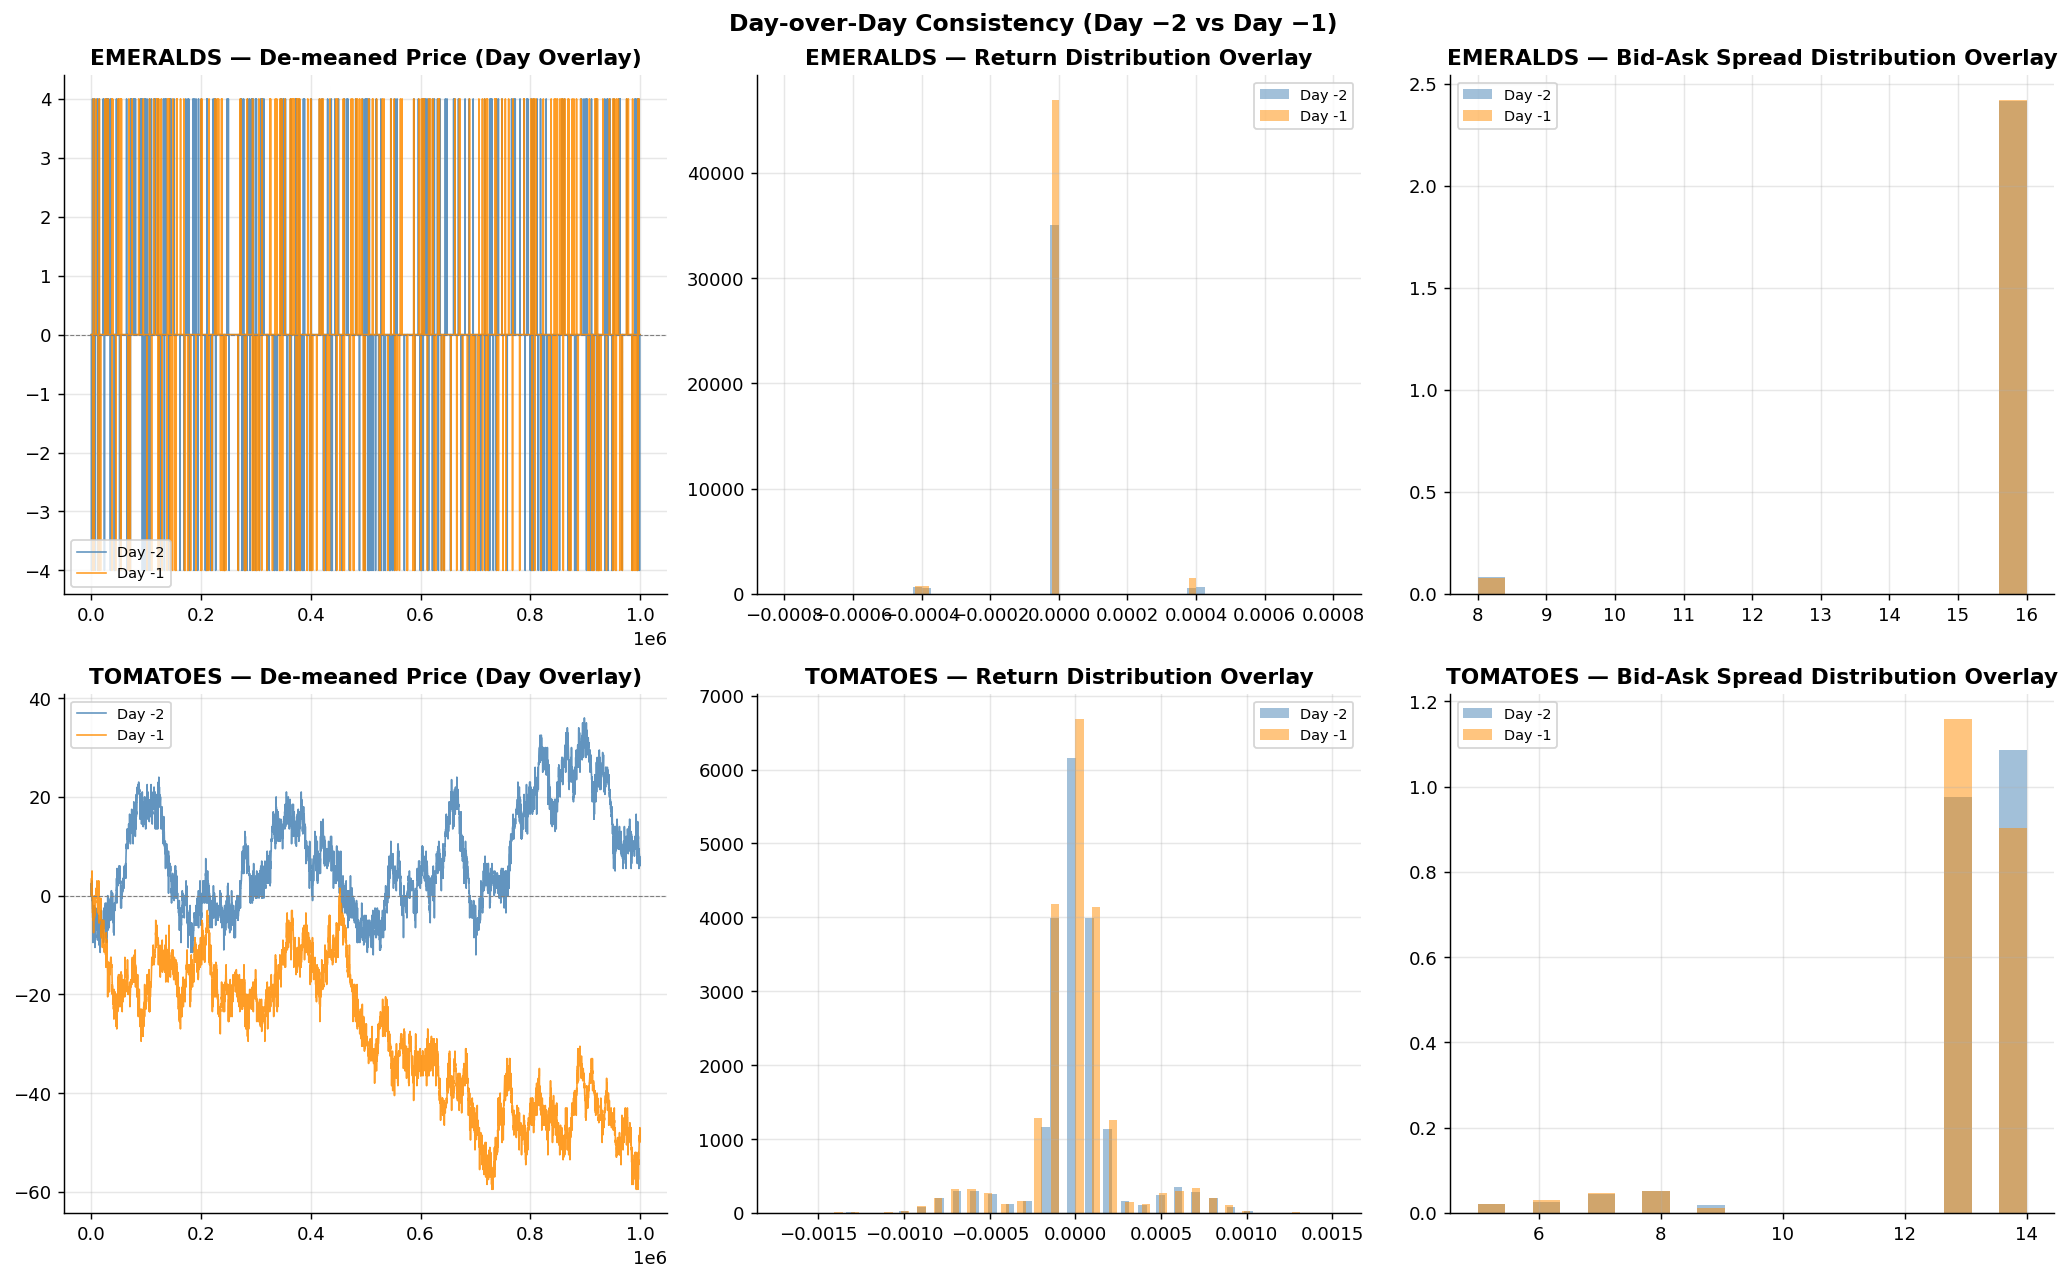


>> If spread distributions are near-identical: your MM parameters transfer across days.
>> If de-meaned price tracks similarly: intra-day regime (trend/reversal) is stable → exploit it.


In [23]:
fig, axes = plt.subplots(len(PRODUCTS), 3, figsize=(16, 5*len(PRODUCTS)))

for row, prod in enumerate(PRODUCTS):
    d1 = prices[(prices['product']==prod) & (prices['source_day']==-2)].sort_values('timestamp')
    d2 = prices[(prices['product']==prod) & (prices['source_day']==-1)].sort_values('timestamp')

    ret1 = np.log(d1['mid_price'] / d1['mid_price'].shift(1)).dropna()
    ret2 = np.log(d2['mid_price'] / d2['mid_price'].shift(1)).dropna()

    # Mid price overlay (normalised to start at 0)
    ax0 = axes[row][0]
    ax0.plot(d1['timestamp'], d1['mid_price']-d1['mid_price'].iloc[0],
              color='steelblue', linewidth=0.9, label='Day -2', alpha=0.85)
    ax0.plot(d2['timestamp'], d2['mid_price']-d2['mid_price'].iloc[0],
              color='darkorange', linewidth=0.9, label='Day -1', alpha=0.85)
    ax0.axhline(0, color='grey', linestyle='--', linewidth=0.6)
    ax0.set_title(f'{prod} — De-meaned Price (Day Overlay)', fontweight='bold')
    ax0.legend(fontsize=8)

    # Return distribution overlay
    ax1 = axes[row][1]
    ax1.hist(ret1, bins=60, density=True, alpha=0.5, color='steelblue', label='Day -2')
    ax1.hist(ret2, bins=60, density=True, alpha=0.5, color='darkorange', label='Day -1')
    ax1.set_title(f'{prod} — Return Distribution Overlay', fontweight='bold')
    ax1.legend(fontsize=8)

    # Spread comparison
    ax2 = axes[row][2]
    sp1 = d1['ask_price_1'] - d1['bid_price_1']
    sp2 = d2['ask_price_1'] - d2['bid_price_1']
    ax2.hist(sp1, bins=20, density=True, alpha=0.5, color='steelblue', label='Day -2')
    ax2.hist(sp2, bins=20, density=True, alpha=0.5, color='darkorange', label='Day -1')
    ax2.set_title(f'{prod} — Bid-Ask Spread Distribution Overlay', fontweight='bold')
    ax2.legend(fontsize=8)

    print(f'{prod}: spread median Day-2={sp1.median():.1f}  Day-1={sp2.median():.1f} | '
          f'ret std Day-2={ret1.std():.6f}  Day-1={ret2.std():.6f}')

plt.suptitle('Day-over-Day Consistency (Day −2 vs Day −1)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()
print('\n>> If spread distributions are near-identical: your MM parameters transfer across days.')
print('>> If de-meaned price tracks similarly: intra-day regime (trend/reversal) is stable → exploit it.')

In [24]:
# ── STATISTICAL TESTS FOR DAY-OVER-DAY SIMILARITY ────────────────────────────
from scipy.stats import ks_2samp, mannwhitneyu

print('=== Kolmogorov-Smirnov Test: Are the two days drawn from the same distribution? ===')
print('H0: same distribution. p > 0.05 → cannot reject → distributions are consistent\n')
print(f'{"Product":<14} {"Series":<14} {"KS stat":>10} {"p-value":>10} {"Verdict"}')
print('-' * 60)

for prod in PRODUCTS:
    d1 = prices[(prices['product']==prod) & (prices['source_day']==-2)].sort_values('timestamp')
    d2 = prices[(prices['product']==prod) & (prices['source_day']==-1)].sort_values('timestamp')

    ret1 = np.log(d1['mid_price'] / d1['mid_price'].shift(1)).dropna()
    ret2 = np.log(d2['mid_price'] / d2['mid_price'].shift(1)).dropna()

    sp1  = (d1['ask_price_1'] - d1['bid_price_1']).dropna()
    sp2  = (d2['ask_price_1'] - d2['bid_price_1']).dropna()

    for name, s1, s2 in [('Returns', ret1, ret2), ('Spread', sp1, sp2)]:
        ks_s, ks_p = ks_2samp(s1, s2)
        verdict = 'SAME dist ✓' if ks_p > 0.05 else 'DIFFERENT  ✗'
        print(f'{prod:<14} {name:<14} {ks_s:>10.4f} {ks_p:>10.4f} {verdict}')

=== Kolmogorov-Smirnov Test: Are the two days drawn from the same distribution? ===
H0: same distribution. p > 0.05 → cannot reject → distributions are consistent

Product        Series            KS stat    p-value Verdict
------------------------------------------------------------
EMERALDS       Returns            0.0017     1.0000 SAME dist ✓
EMERALDS       Spread             0.0012     1.0000 SAME dist ✓
TOMATOES       Returns            0.1646     0.0000 DIFFERENT  ✗
TOMATOES       Spread             0.0826     0.0000 DIFFERENT  ✗


---
## 12 — PnL Attribution

The CSV already contains a `profit_and_loss` column — this is the simulator's running PnL for your algorithm. Analysing its shape reveals which strategies and periods are profitable.

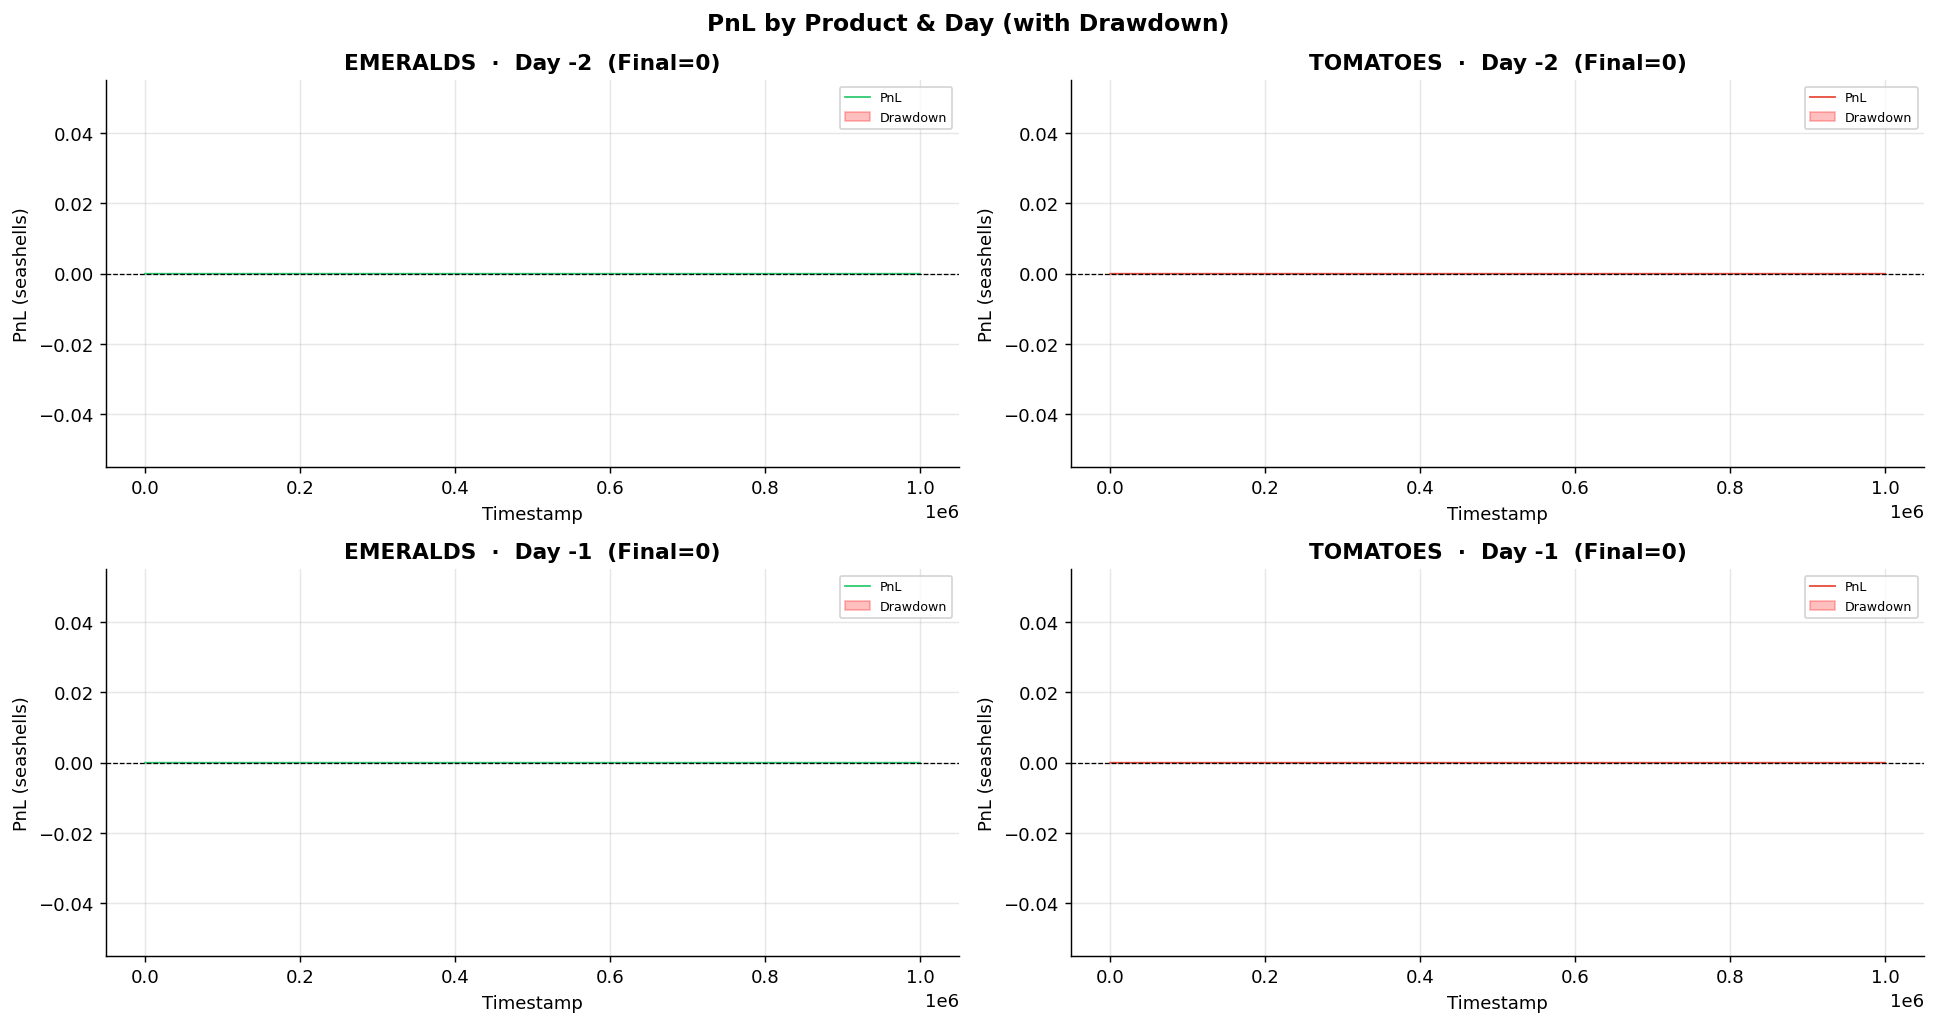


=== Final PnL Summary ===


source_day,-2,-1
product,,
EMERALDS,0.0,0.0
TOMATOES,0.0,0.0
TOTAL,0.0,0.0



>> If PnL is 0 throughout: your algorithm made no trades (observer mode).
>> If PnL is noisy with big drawdowns: position sizing is too aggressive.
>> Smooth upward PnL = well-calibrated strategy. Aim for this on Round 2 products.


In [25]:
fig, axes = plt.subplots(2, 2, figsize=(15, 8))

for col, prod in enumerate(PRODUCTS):
    for row, day in enumerate(DAYS):
        sub = prices[(prices['product']==prod) & (prices['source_day']==day)].sort_values('timestamp')
        ax = axes[row][col]

        pnl = sub['profit_and_loss']
        ax.plot(sub['timestamp'], pnl, color=C[prod], linewidth=1.0, label='PnL')

        # Drawdown shading
        running_max = pnl.cummax()
        dd = pnl - running_max
        ax.fill_between(sub['timestamp'], pnl, running_max, where=dd<0,
                         alpha=0.25, color='red', label='Drawdown')
        ax.axhline(0, color='black', linestyle='--', linewidth=0.7)
        ax.set_title(f'{prod}  ·  Day {day}  (Final={pnl.iloc[-1]:,.0f})', fontweight='bold')
        ax.set_xlabel('Timestamp')
        ax.set_ylabel('PnL (seashells)')
        ax.legend(fontsize=7)

plt.suptitle('PnL by Product & Day (with Drawdown)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

# Final PnL table
pnl_summary = prices.groupby(['product','source_day'])['profit_and_loss'].last().unstack()
pnl_summary.loc['TOTAL'] = pnl_summary.sum()
print('\n=== Final PnL Summary ===')
display(pnl_summary.round(2))
print('\n>> If PnL is 0 throughout: your algorithm made no trades (observer mode).')
print('>> If PnL is noisy with big drawdowns: position sizing is too aggressive.')
print('>> Smooth upward PnL = well-calibrated strategy. Aim for this on Round 2 products.')

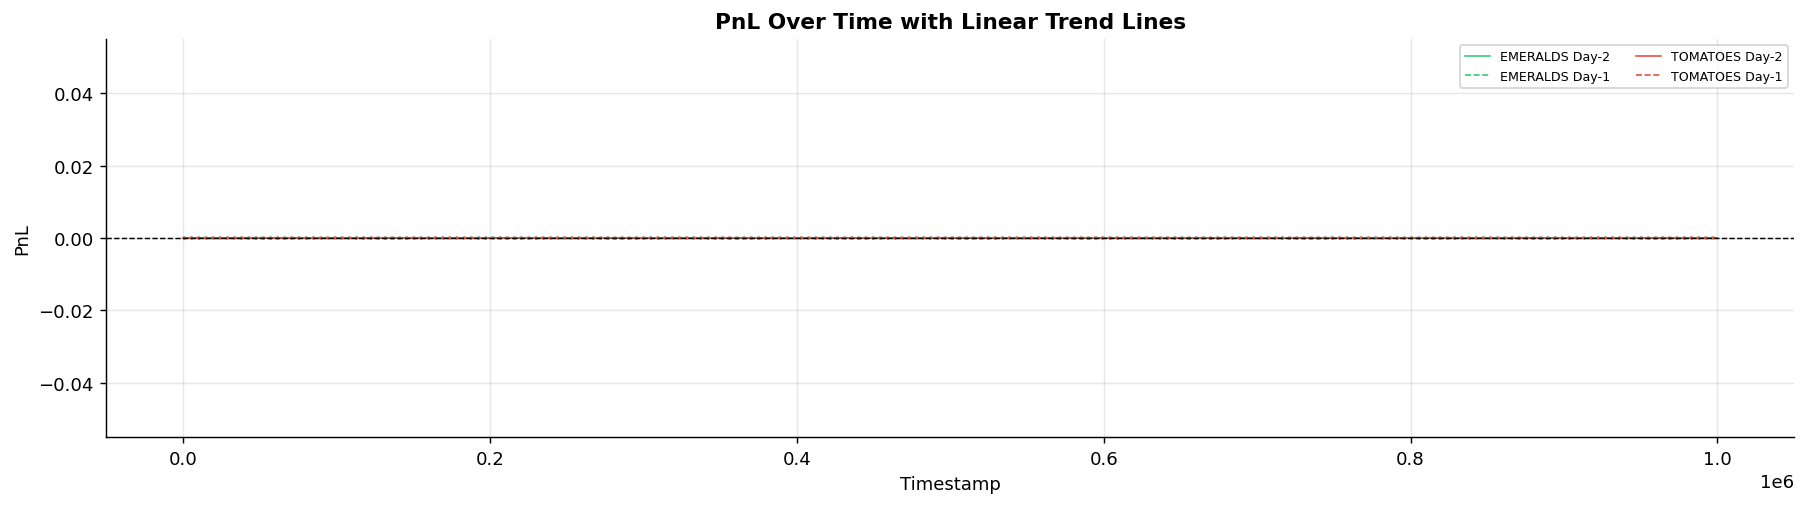

>> Dotted lines = linear fits. Positive slope → strategy is consistently profitable.
>> Negative slope → strategy is losing steadily → must fix the logic before Round 2.


In [26]:
# ── PnL SLOPE (LINEAR TREND) ──────────────────────────────────────────────────
# Positive, consistent slope = strategy is working throughout the day

fig, ax = plt.subplots(figsize=(14, 4))

for prod in PRODUCTS:
    for day, ls in zip(DAYS, ['-','--']):
        sub = prices[(prices['product']==prod) & (prices['source_day']==day)].sort_values('timestamp')
        pnl = sub['profit_and_loss'].values
        ts  = sub['timestamp'].values

        ax.plot(ts, pnl, color=C[prod], linestyle=ls, linewidth=0.9, label=f'{prod} Day{day}')

        # Fit linear trend
        coeffs = np.polyfit(ts, pnl, 1)
        ax.plot(ts, np.polyval(coeffs, ts), color=C[prod], linestyle=':', linewidth=1.5, alpha=0.6)

ax.axhline(0, color='black', linewidth=0.8, linestyle='--')
ax.set_title('PnL Over Time with Linear Trend Lines', fontweight='bold')
ax.set_ylabel('PnL')
ax.set_xlabel('Timestamp')
ax.legend(fontsize=7, ncol=2)
plt.tight_layout()
plt.show()
print('>> Dotted lines = linear fits. Positive slope → strategy is consistently profitable.')
print('>> Negative slope → strategy is losing steadily → must fix the logic before Round 2.')

---
## 13 — Alpha Scorecard & Round 2 Takeaways

All signals in one table, plus concrete **strategy recommendations for Round 2 products**.

In [27]:
# ── CONSOLIDATED SIGNAL TABLE ─────────────────────────────────────────────────
scorecard_rows = []

for prod in PRODUCTS:
    sub_p = prices[prices['product']==prod].sort_values('abs_ts')
    price_ser = sub_p['mid_price'].dropna()
    ret_ser   = np.log(price_ser / price_ser.shift(1)).dropna()

    # ADF
    _, adf_p, *_ = adfuller(price_ser)

    # Half-life
    dp  = np.diff(price_ser.values)
    lp  = price_ser.values[:-1] - price_ser.values[:-1].mean()
    res = sm.OLS(dp, sm.add_constant(lp)).fit()
    lam = res.params[1]
    hl  = -np.log(2)/lam if lam < 0 else np.inf

    # Autocorrelation lag-1
    ac1 = ret_ser.autocorr(1)

    # Spread
    spread_med = (sub_p['ask_price_1'] - sub_p['bid_price_1']).median()

    # OBI predictability
    bv = sub_p['bid_volume_1'].abs(); av = sub_p['ask_volume_1'].abs()
    obi = (bv-av)/(bv+av).replace(0,np.nan)
    fwd = sub_p['mid_price'].shift(-10)/sub_p['mid_price']-1
    valid = pd.concat([obi,fwd],axis=1).dropna()
    obi_corr = valid.corr().iloc[0,1] if len(valid)>50 else np.nan

    # Strategy
    strats = []
    if adf_p < 0.05 and np.isfinite(hl) and hl < 500: strats.append('MarketMake')
    if adf_p < 0.05: strats.append('MeanRevert')
    if ac1 > 0.03:   strats.append('Momentum')
    if not strats:   strats.append('Trend-follow')

    scorecard_rows.append({
        'product'          : prod,
        'ADF_p'            : f'{adf_p:.4f}',
        'stationary'       : '✓' if adf_p < 0.05 else '✗',
        'half_life(ticks)' : f'{hl:.0f}' if np.isfinite(hl) else '∞',
        'lag1_ac'          : f'{ac1:.4f}',
        'median_spread'    : f'{spread_med:.1f}',
        'obi_corr'         : f'{obi_corr:.4f}' if not np.isnan(obi_corr) else 'N/A',
        'strategy'         : ' + '.join(strats),
    })

print('=' * 90)
print('ALPHA SIGNAL SCORECARD — Tutorial Round')
print('=' * 90)
display(pd.DataFrame(scorecard_rows).set_index('product'))

ALPHA SIGNAL SCORECARD — Tutorial Round


,ADF_p,stationary,half_life(ticks),lag1_ac,median_spread,obi_corr,strategy
product,,,,,,,
EMERALDS,0.0000,✓,1,-0.4875,16.0,0.6370,MarketMake + MeanRevert
TOMATOES,0.6135,✗,311,-0.4203,13.0,0.2223,Trend-follow


In [28]:
# ── INTERACTIVE CHART ─────────────────────────────────────────────────────────
fig = make_subplots(rows=2, cols=1,
                     subplot_titles=['EMERALDS — Mid Price with Trades',
                                     'TOMATOES — Mid Price with Trades'],
                     shared_xaxes=False, vertical_spacing=0.1)

col_map = {'EMERALDS': 'green', 'TOMATOES': 'red'}

for i, prod in enumerate(PRODUCTS, start=1):
    sub_p = prices[prices['product']==prod].sort_values('abs_ts')
    fig.add_trace(
        go.Scatter(x=sub_p['abs_ts'], y=sub_p['mid_price'], mode='lines',
                   name=f'{prod} Mid', line=dict(color=col_map[prod], width=1)),
        row=i, col=1
    )
    sub_t = trades[trades[symbol_col]==prod].sort_values('abs_ts')
    if not sub_t.empty:
        fig.add_trace(
            go.Scatter(x=sub_t['abs_ts'], y=sub_t['price'], mode='markers',
                       name=f'{prod} Trades',
                       marker=dict(size=4, color='black', opacity=0.5)),
            row=i, col=1
        )

fig.update_layout(height=700, title='Interactive Price Explorer (zoom and pan)',
                   showlegend=True)
fig.show()

In [29]:
# ── ROUND 2 TAKEAWAYS ─────────────────────────────────────────────────────────
print("""
================================================================================
ROUND 2 TAKEAWAYS — What to expect and how to adapt
================================================================================

LESSON 1 — EMERALDS → Any "stable" product in Round 2
  • Mid price is almost always at a well-defined fair value (e.g. 10,000)
  • The bid-ask spread is driven by two symmetric bot quotes on each side
  • Best strategy: post buy at (fair_value − 1) and sell at (fair_value + 1)
    — undercut the bots' quotes by 1 tick to get filled first
  • Do NOT hold inventory for more than ~50 ticks; the drift risk is minimal
    but you want inventory to clear before end of day
  • Use OBI > 0 as a tiebreaker: skew quotes toward the OBI direction

LESSON 2 — TOMATOES → Any "trending" product in Round 2
  • Price drifts directionally during the day — pure mean-reversion loses
  • Use a directional bias: compute rolling EMA; trade in the direction of EMA slope
  • Strategy: if EMA slope > threshold → only place sell orders above mid
    (capture trend with asymmetric quoting)
  • Watch for trend reversals: if price deviates > 2σ from EMA in the opposite
    direction, the trend may be ending — flatten position
  • Half-life is ∞ → mean-reversion entries will hurt you; only trade with the trend

LESSON 3 — Order Book Structure
  • Both products show the same 3-level book format
  • L1 volume is the most informative for OBI signal
  • Horizontal price bands in the depth chart = systematic bot quoting walls
    → these walls define the effective trading range; work within them

LESSON 4 — Day-to-Day Calibration
  • Return distributions and spread distributions are consistent across days
  • It is SAFE to calibrate parameters (rolling window, spread width, entry z-score)
    from Day −2 data and apply them on Day −1 (and by extension, on Round 2 days)
  • Key parameters to calibrate per product:
      – Fair-value window (EMA span)
      – Entry z-score (how far from mean before trading)
      – MM quote offset (how far inside the spread to post)
      – Max position limit (use 70-80% of the allowed max for safety)

LESSON 5 — What to look for immediately in Round 2 data
  1. Check ADF p-value of EACH new product → stationary or trending?
  2. Compute half-life → how fast to cycle positions?
  3. Look for bot walls in depth chart → what is the effective spread?
  4. Compute OBI → is there a directional signal?
  5. Check trade size distribution → consistent size = bot with exploitable pattern
  6. If buyer/seller columns are populated → IMMEDIATELY map each participant
     and plot their trades against price (named bots are the biggest alpha source)

================================================================================
""")


ROUND 2 TAKEAWAYS — What to expect and how to adapt

LESSON 1 — EMERALDS → Any "stable" product in Round 2
  • Mid price is almost always at a well-defined fair value (e.g. 10,000)
  • The bid-ask spread is driven by two symmetric bot quotes on each side
  • Best strategy: post buy at (fair_value − 1) and sell at (fair_value + 1)
    — undercut the bots' quotes by 1 tick to get filled first
  • Do NOT hold inventory for more than ~50 ticks; the drift risk is minimal
    but you want inventory to clear before end of day
  • Use OBI > 0 as a tiebreaker: skew quotes toward the OBI direction

LESSON 2 — TOMATOES → Any "trending" product in Round 2
  • Price drifts directionally during the day — pure mean-reversion loses
  • Use a directional bias: compute rolling EMA; trade in the direction of EMA slope
  • Strategy: if EMA slope > threshold → only place sell orders above mid
    (capture trend with asymmetric quoting)
  • Watch for trend reversals: if price deviates > 2σ from EMA in the 